# 1. Imports and Setup

## Package Importation

In [2]:
#Import NumPy and pandas
import numpy as np
import pandas as pd

#Import matplotlib libraries
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

#Import datetime libraries
import datetime

#Import math
import math

#Import PuLP
import pulp

#Import Dataclasses
from dataclasses import dataclass

#Import Pairwise
from itertools import pairwise

## Dataset Details

The generated simulation info is;
📍 Location: TAS - Hobart - Cool Temperate | 🗓️ Period: 2023 to 2024 | 🏠 Load: 23W0219.parquet (x 23.6) | ☀️ Solar PV: PR 85% | Temp Coeff -0.004 / °C


and the tariff details are;

#### Flat Tariff
Import: 0.3 AUD/MWh

Export: 0.05 AUD/MWh

#### ToU Tariff
Import
- Peak: 0.4 AUD/MWh
- Shoulder: 0.25 AUD/MWh
- Off-Peak: 0.15 AUD/MWh

Export: 0.05 AUD/MWh

#### Wholesale/Spot Price
Import/Export: taken directly from market spot price data

## Data Importation

In [3]:
DATA_PATH = "./Data_TAS_Hobart - Cool Temperate_2023-2024_partial.csv"
SPOT_PRICE_2024 = "./PRICE_AND_DEMAND_202401_TAS1.csv"
FORECAST_PRICES_2024 = "./forecast_prices_2024.csv"
data_raw = pd.read_csv(DATA_PATH)
spot_price_2024_raw = pd.read_csv(SPOT_PRICE_2024)
forecast_price_2024_raw = pd.read_csv(FORECAST_PRICES_2024)
data_raw["timestamp"] = pd.to_datetime(data_raw["timestamp"], dayfirst = True)
spot_price_2024_raw["SETTLEMENTDATE"] = pd.to_datetime(spot_price_2024_raw["SETTLEMENTDATE"], dayfirst = True)

# 2. First Inspection of Raw Data

## Data Description

In [4]:
data_raw.describe()

,timestamp,irradiance_W/m^2,temperature_C,solar_output_kW,commercial_forecasted_solar_output_kW,load_kW,spot_price_AUD/kWh,tariff_import_flat_AUD/kWh,tariff_export_flat_AUD/kWh,tariff_import_tou_AUD/kWh,tariff_export_tou_AUD/kWh
count,210528,209477.000000,209477.000000,104519.000000,105408.000000,209475.000000,105120.000000,2.105280e+05,2.105280e+05,210528.000000,2.105280e+05
mean,2024-01-01 11:57:29.999999232,161.468023,12.868561,1.231844,1.285633,0.983629,0.055732,3.000000e-01,5.000000e-02,0.241667,5.000000e-02
min,2023-01-01 00:00:00,0.000000,1.100000,0.000000,0.000000,0.000000,-0.998070,3.000000e-01,5.000000e-02,0.150000,5.000000e-02
25%,2023-07-02 17:58:45,0.000000,9.500000,0.000000,0.000000,0.670000,0.012140,3.000000e-01,5.000000e-02,0.150000,5.000000e-02
50%,2024-01-01 11:57:30,12.000000,12.600000,0.100000,0.100000,0.740000,0.054280,3.000000e-01,5.000000e-02,0.250000,5.000000e-02
75%,2024-07-02 05:56:15,274.000000,15.700000,2.085000,2.170000,0.890000,0.081900,3.000000e-01,5.000000e-02,0.250000,5.000000e-02
max,2024-12-31 23:55:00,1040.000000,34.100000,10.090000,8.030000,8.870000,15.500000,3.000000e-01,5.000000e-02,0.400000,5.000000e-02
std,NaN,235.430061,4.819340,1.800467,1.873579,0.733211,0.086538,5.551128e-17,6.938910e-18,0.083749,6.938910e-18


## Timestamp Duplicate Check

Check if the timestamp is unique

In [5]:
data_raw["timestamp"].is_unique

True

Check is the expected number of timestamps are present (the range is seen to be correct from the data description)

In [6]:
expected_ts = 60 / 5 * 24 * 365 * 2 + 60 / 5 * 24 #2024 is a leap year, so we have 366 days in 2024
len(data_raw) == expected_ts

True

## Add Datetime Columns

Adding various columns related to datetime for analysis later on

In [7]:
data_raw["hour"] = data_raw["timestamp"].dt.hour
data_raw["date"] = data_raw["timestamp"].dt.date
data_raw["month"] = data_raw["timestamp"].dt.month
data_raw["year"] = data_raw["timestamp"].dt.year
data_raw["month_name"] = data_raw["timestamp"].dt.month_name()
data_raw["time_label"] = data_raw["timestamp"].dt.strftime("%H:%M")
data_raw["day_of_week"] = data_raw["timestamp"].dt.strftime("%A")
data_raw["half_hour_index"] = data_raw["timestamp"].dt.hour * 2 + data_raw["timestamp"].dt.minute // 30

## Missing Data

First step is to flag the the missing data

In [8]:
missing_irradiance = data_raw["irradiance_W/m^2"].isna()
missing_temperature = data_raw["temperature_C"].isna()
missing_solaroutput = np.where(data_raw["year"] == 2023, data_raw["solar_output_kW"].isna(), False)
missing_load = data_raw["load_kW"].isna()

missing_dates = data_raw.loc[missing_irradiance | missing_temperature | missing_solaroutput | missing_load, "date"]

Number of days missing data

In [9]:
len(missing_dates.unique())

32

In [10]:
#Only 17th/18th of the 5th 2023 has a full day of missing data. 
#Other consequtive dates of missing data are due to the missing data spanning over midnight 

From inspecting the raw files, it can be seen that only the 17th/18th of May 2023 has a full missing day of missing data and the other consequitive dates just span over midnight. This means that previous and past days can be averaged to fill in the missing data. Two methods of fill in were inspected, the first averaging the day before and after, and the second averaging the week before and after.

In [11]:
#Taken from GitHub Copilot and personally modified
def fill_missing_values_day(df, column_name):
    out = df.copy()
    values_by_time = out.set_index("timestamp")[column_name]

    missing = out[column_name].isna()
    missing_times = out.loc[missing, "timestamp"]

    previous = values_by_time.reindex(
        missing_times - pd.Timedelta(days=1)
        ).to_numpy()
    following = values_by_time.reindex(
        missing_times + pd.Timedelta(days=1)
        ).to_numpy()


    out.loc[missing, column_name] = (previous + following) / 2
    return out

In [12]:
#Modified from previous Copilot code by Claude
def fill_missing_values_week(df, column_name, max_days=7):
    out = df.copy()
    values_by_time = out.set_index("timestamp")[column_name]

    missing = out[column_name].isna()
    missing_times = out.loc[missing, "timestamp"]

    neighbours = []
    for n in range(1, max_days + 1):
        for sign in (-1, 1):
            neighbours.append(
                values_by_time.reindex(missing_times + sign * pd.Timedelta(days=n)).to_numpy()
            )

    fill = np.nanmean(np.vstack(neighbours), axis=0)     # one value per missing row
    out.loc[missing, column_name] = fill
    return out

Each column missing data was inspected with the two fill methods and using the eye test, determined which method produced the most accurate fill. The graph inspection below has been turned into quotations as it doesn"t need to be run every time

In [13]:
#Check whether week or day fill is better 
"""
for n in missing_dates.unique():
    value_col = "load_kW"
    dfday = fill_missing_values_day(data_raw, value_col)
    dfweek = fill_missing_values_week(data_raw, value_col)
    target_date = n
    h = dfday[dfday["date"] == target_date][["date", "time_label", value_col]]
    w = dfweek[dfweek["date"] == target_date][["date", "time_label", value_col]]
    g = data_raw[data_raw["date"] == target_date][["date", "time_label", value_col]]
    fig, ax = plt.subplots(figsize=(12,4))
    ax.plot(h["time_label"], h[value_col], label = "Filled Day")
    ax.plot(w["time_label"], w[value_col], label = "Filled Week")
    ax.plot(g["time_label"], g[value_col], label = "Original Data")
    ax.set_xlabel("Time")
    ax.set_ylabel(value_col)
    ax.set_xticks(range(0, 288, 24))
    ax.legend()
    fig.tight_layout()
    """

'\nfor n in missing_dates.unique():\n    value_col = "load_kW"\n    dfday = fill_missing_values_day(data_raw, value_col)\n    dfweek = fill_missing_values_week(data_raw, value_col)\n    target_date = n\n    h = dfday[dfday["date"] == target_date][["date", "time_label", value_col]]\n    w = dfweek[dfweek["date"] == target_date][["date", "time_label", value_col]]\n    g = data_raw[data_raw["date"] == target_date][["date", "time_label", value_col]]\n    fig, ax = plt.subplots(figsize=(12,4))\n    ax.plot(h["time_label"], h[value_col], label = "Filled Day")\n    ax.plot(w["time_label"], w[value_col], label = "Filled Week")\n    ax.plot(g["time_label"], g[value_col], label = "Original Data")\n    ax.set_xlabel("Time")\n    ax.set_ylabel(value_col)\n    ax.set_xticks(range(0, 288, 24))\n    ax.legend()\n    fig.tight_layout()\n    '

Cleaned DF code is produced with missing values filled in

In [14]:
#Cleaned data frame with missing values filled in
df = []
df = fill_missing_values_week(data_raw, "irradiance_W/m^2")
df = fill_missing_values_day(df, "temperature_C")
df = fill_missing_values_week(df, "load_kW")

filled = fill_missing_values_week(df, "solar_output_kW")
mask = df["year"] == 2023
df.loc[mask, "solar_output_kW"] = filled.loc[mask, "solar_output_kW"]

cols = ["timestamp", "irradiance_W/m^2", "temperature_C", "load_kW", "solar_output_kW"]
for col in cols:
    df[f"{col}_was_filled"] = data_raw[col].isna()

C:\Users\jackh\AppData\Local\Temp\ipykernel_15708\3141861613.py:16: RuntimeWarning: Mean of empty slice
  fill = np.nanmean(np.vstack(neighbours), axis=0)     # one value per missing row


## Power to Energy Conversions

Important columns to be added in converting power to energy (kW -> kWh)

In [15]:
time_factor = 5/60
df["solar_output_kWh"] = df["solar_output_kW"] * time_factor
df["commercial_forecasted_solar_output_kWh"] = df["commercial_forecasted_solar_output_kW"] * time_factor
df["load_kWh"] = df["load_kW"] * time_factor

## Zero Load Inspection

Inspecting the zero load times and including some potential causes for the zero load

In [16]:
df[df["load_kW"] < 0.3][["timestamp", "load_kW", "spot_price_AUD/kWh", "temperature_C"]]

,timestamp,load_kW,spot_price_AUD/kWh,temperature_C
87785,2023-11-01 19:25:00,0.0,0.07020,12.9
87786,2023-11-01 19:30:00,0.0,0.07024,12.8
87787,2023-11-01 19:35:00,0.0,0.07020,12.7
87788,2023-11-01 19:40:00,0.0,0.07020,12.6
87789,2023-11-01 19:45:00,0.0,0.07024,12.5
87790,2023-11-01 19:50:00,0.0,0.07024,12.4
87791,2023-11-01 19:55:00,0.0,0.07020,12.3
87792,2023-11-01 20:00:00,0.0,0.06630,12.2
87793,2023-11-01 20:05:00,0.0,0.07020,12.1
87794,2023-11-01 20:10:00,0.0,0.07020,12.1


Two events of zero code with nothing unusual in regards to spot price, time, or temperature. Assumed to be a blackout or an internal household issue and ultimately ignored

## High Load Inspection

In [17]:
df[df["load_kW"] > 7][["timestamp", "load_kW", "spot_price_AUD/kWh", "temperature_C"]]

,timestamp,load_kW,spot_price_AUD/kWh,temperature_C
56240,2023-07-15 06:40:00,7.89,0.00026,8.3
56241,2023-07-15 06:45:00,7.94,-0.00561,8.2
56242,2023-07-15 06:50:00,8.87,0.00026,8.2
56243,2023-07-15 06:55:00,8.41,-0.00561,8.2
56244,2023-07-15 07:00:00,8.11,-0.00561,8.1
56245,2023-07-15 07:05:00,8.00,-0.00561,8.1
103927,2023-12-27 20:35:00,8.31,0.09151,18.4
103928,2023-12-27 20:40:00,8.84,0.09154,18.3
103934,2023-12-27 21:10:00,7.80,0.09044,17.9
103940,2023-12-27 21:40:00,7.98,0.09092,17.6


## Net Load Creation

In [18]:
df["net_load_kW"] = np.where(df["year"] == 2023, 
                            df["load_kW"] - df["solar_output_kW"], 
                            df["load_kW"] - df["commercial_forecasted_solar_output_kW"])
df["net_load_kWh"] = np.where(df["year"] == 2023, 
                              df["load_kWh"] - df["solar_output_kWh"], 
                              df["load_kWh"] - df["commercial_forecasted_solar_output_kWh"])
df["negative_net_load_kW"] = np.where(df["net_load_kW"] < 0, df["net_load_kW"], 0)
df["negative_net_load_kWh"] = np.where(df["net_load_kWh"] < 0, df["net_load_kWh"], 0)
df["positive_net_load_kW"] = np.where(df["net_load_kW"] > 0, df["net_load_kW"], 0)
df["positive_net_load_kWh"] = np.where(df["net_load_kWh"] > 0, df["net_load_kWh"], 0)

## Resampled Data

Creating 30 minute, daily and monthly aggregations of the data. Temperature, irradiance, and power are aggregated via mean, energy is aggregated via sum, and tariffs are aggregated via mean

In [19]:
agg = {
    "irradiance_W/m^2": "mean",
    "temperature_C": "mean",
    "load_kW": "mean",
    "solar_output_kW": "mean",
    "commercial_forecasted_solar_output_kW": "mean",
    "net_load_kW": "mean",
    "negative_net_load_kW": "mean",
    "positive_net_load_kW": "mean",
    "load_kWh": "sum",
    "solar_output_kWh": "sum",
    "commercial_forecasted_solar_output_kWh": "sum",
    "net_load_kWh": "sum",
    "negative_net_load_kWh": "sum",
    "positive_net_load_kWh": "sum",
    "tariff_import_flat_AUD/kWh": "mean",
    "tariff_export_flat_AUD/kWh": "mean",
    "tariff_import_tou_AUD/kWh": "mean",
    "tariff_export_tou_AUD/kWh": "mean",
}
df = df.set_index("timestamp")

df_30min = df.resample("30min").agg(agg).reset_index()
df_daily = df.resample("D").agg(agg).reset_index()
df_monthly = df.resample("ME").agg(agg).reset_index()

df = df.reset_index()

## Typical Daily Profiles

In [20]:
#From wk1 workshop
def typical_daily_profile(df_30min, month, value_col, datetime_col="timestamp"):
    df = df_30min.copy()
    df = df[df[datetime_col].dt.month == month]
    df["time"] = df[datetime_col].dt.time
    profile = df.groupby("time")[value_col].mean().reset_index()
    profile[datetime_col] = pd.to_datetime(profile["time"].astype(str), format="%H:%M:%S")
    profile = profile[[datetime_col, value_col]]
    return profile

In [21]:
#From WK1 Workshop
def plot_profile(profile, value_col, datetime_col="timestamp"):
    dfp = profile.copy()
    dfp[datetime_col] = pd.to_datetime(dfp[datetime_col], errors="coerce")
    dfp = dfp.dropna(subset=[datetime_col]).sort_values(datetime_col)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(dfp[datetime_col], dfp[value_col], marker="o", linewidth=1.5)

    ax.set_title("Typical Daily Profile (30-min average)")
    ax.set_xlabel("Time of day")
    ax.set_ylabel(value_col)
    ax.grid(True, alpha=0.3)

    # Show time-of-day nicely: ticks every 2 hours
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.xticks(rotation=45)
    plt.tight_layout()

    return fig, ax

Getting monthly data for whatever value is needed

In [149]:
daily_profiles = []
for n in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:
    df_profile = typical_daily_profile(df_30min, n, "solar_output_kW")
    daily_profiles.append(df_profile.max())

print(daily_profiles)

[timestamp          1900-01-01 23:30:00
solar_output_kW               5.453172
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               4.568512
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               4.067285
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               2.906833
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               2.450426
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               2.241222
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               2.315265
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               3.048656
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               4.294667
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               4.693602
dtype: object, timestamp          1900-01-01 23:30:00
solar_output_kW               

# 3. PV Sizing and Predictions

## Sizing PV Based on 2023 Outputs and 2024 Forecasts

The first step of solar sizing involves sizing the system based off of max outputs

In [24]:
PV_PR = 0.85
temp_coeff = -0.004
def initial_solar_sizing(df,df_column_name):
    temp_at_max_pv = df.loc[df[df_column_name].idxmax(), "temperature_C"]
    irradiance_at_max_pv = df.loc[df[df_column_name].idxmax(), "irradiance_W/m^2"]
    max_pv_output = df[df_column_name].max()
    rated_capacity = max_pv_output / (PV_PR * (irradiance_at_max_pv/1000) * (1 + temp_coeff * (temp_at_max_pv - 25)))

    return {"rated_capacity": rated_capacity, 
            "temp_at_max_pv": temp_at_max_pv, 
            "irradiance_at_max_pv": irradiance_at_max_pv, 
            "max_pv_output": max_pv_output}

In [25]:
pv_actual_2023 = initial_solar_sizing(df, "solar_output_kW")
pv_forecasted_2024 = initial_solar_sizing(df, "commercial_forecasted_solar_output_kW")

print(f"PV rated capacity for 2023: {pv_actual_2023['rated_capacity']} kW")
print(f"PV rated capacity for 2024: {pv_forecasted_2024['rated_capacity']} kW")
print(f"Temperature in 2023 at max PV output: {pv_actual_2023['temp_at_max_pv']} °C")
print(f"Temperature in 2024 at max PV output: {pv_forecasted_2024['temp_at_max_pv']} °C")
print(f"Irradiance in 2023 at max PV output: {pv_actual_2023['irradiance_at_max_pv']} W/m^2")
print(f"Irradiance in 2024 at max PV output: {pv_forecasted_2024['irradiance_at_max_pv']} W/m^2")
print(f"Max PV output in 2023: {pv_actual_2023['max_pv_output']} kW")
print(f"Max PV output in 2024: {pv_forecasted_2024['max_pv_output']} kW")

PV rated capacity for 2023: 11.513664631711077 kW
PV rated capacity for 2024: 9.023516610282611 kW
Temperature in 2023 at max PV output: 25.0 °C
Temperature in 2024 at max PV output: 19.4 °C
Irradiance in 2023 at max PV output: 1031.0 W/m^2
Irradiance in 2024 at max PV output: 1024.0 W/m^2
Max PV output in 2023: 10.09 kW
Max PV output in 2024: 8.03 kW


## Statistically Modelling PV Based on 2023 Data

Sizing the PV based off of the statistical error between the model and the actal data

In [26]:
test = df.copy()
given2023_total = test["solar_output_kW"].sum()

mae_results = []
rmse_results = []

for n in np.arange(8.00, 12.00, 0.01):
    test["pv_modelled_kW"] = round(n * PV_PR * (test["irradiance_W/m^2"]/1000) * (1+temp_coeff*(test["temperature_C"]-25)), 2)
    
    modeled2023_total = np.where(test["year"] == 2023, test["pv_modelled_kW"], 0).sum()
    
    mae = 1/len(test[df["year"] == 2023]) *  abs(test["solar_output_kW"] - 
                                               np.where(test["year"] == 2023, test["pv_modelled_kW"], 0)
                                               ).sum()
    mae_results.append(mae)
    rmse = math.sqrt(1/len(test[test["year"] == 2023]) * 
                     ((test["solar_output_kW"] - 
                       np.where(test["year"] == 2023, test["pv_modelled_kW"], 0))**2
                       ).sum())
    rmse_results.append(rmse)

Finding the values that minimises the RMSE and MAE and the combined error of these two error methods

In [27]:
pv_modelling_results = pd.DataFrame()

pv_modelling_results["pv_size_kW"] = np.arange(8.00, 12.00, 0.01) 
pv_modelling_results["mae"] = mae_results
pv_modelling_results["rmse"] = rmse_results
pv_modelling_results["combined_error"] = pv_modelling_results["mae"] + pv_modelling_results["rmse"]

mae_min = round(pv_modelling_results.loc[pv_modelling_results["mae"].idxmin(), "pv_size_kW"], 2)
rmse_min = round(pv_modelling_results.loc[pv_modelling_results["rmse"].idxmin(), "pv_size_kW"], 2)
combined_error_min = round(pv_modelling_results.loc[pv_modelling_results["combined_error"].idxmin(), "pv_size_kW"], 2)

print("MAE min:", mae_min, "kW")
print("RMSE min:", rmse_min, "kW")
print("Combined error min:", combined_error_min, "kW")

MAE min: 8.96 kW
RMSE min: 8.76 kW
Combined error min: 8.84 kW


It was decided that the combined error min would be the size that would be continued for the modelling

## PV Modelling Accuracy

Testing both 2023 and 2024 given datasets for PV output against the model

In [28]:
tested_cap_pv = 8.84

df["pv_modelled_kW"] = round(tested_cap_pv * PV_PR * (df["irradiance_W/m^2"]/1000) * (1+temp_coeff*(df["temperature_C"]-25)), 2)

def modelled_pv_accuracy(df, year):
    if year == 2023:
        column_name = "solar_output_kW"
    elif year == 2024:
        column_name = "commercial_forecasted_solar_output_kW"

    given_total = df[column_name].sum()
    modeled_total = np.where(df["year"] == year, df["pv_modelled_kW"], 0).sum()

    mae = round(1/len(df[df["year"] == year]) *  abs(df[column_name] - np.where(df["year"] == year, df["pv_modelled_kW"], 0)).sum(), 4)
    rmse = round(math.sqrt(1/len(df[df["year"] == year]) * ((df[column_name] - np.where(df["year"] == year, 
                                                                                  df["pv_modelled_kW"], 0))**2).sum()), 4)
    forecast_over_actual = round(modeled_total / given_total * 100, 2)
    return {"given_total": given_total,
            "modeled_total": modeled_total,
            "mae": mae,
            "rmse": rmse,
            "forecast_over_actual": forecast_over_actual
            }

In [29]:
results_test_2023 = modelled_pv_accuracy(df, 2023)
results_test_2024 = modelled_pv_accuracy(df, 2024)

print(f"MAE for 2023: {results_test_2023['mae']}")
print(f"MAE for 2024: {results_test_2024['mae']}")
print(f"RMSE for 2023: {results_test_2023['rmse']}")
print(f"RMSE for 2024: {results_test_2024['rmse']}")
print(f"Forecast over actual for 2023: {results_test_2023['forecast_over_actual']} %")
print(f"Forecast over actual for 2024: {results_test_2024['forecast_over_actual']} %")

MAE for 2023: 0.1328
MAE for 2024: 0.0291
RMSE for 2023: 0.3524
RMSE for 2024: 0.0749
Forecast over actual for 2023: 100.77 %
Forecast over actual for 2024: 98.02 %


## Creating Actual vs Forecasted Columns

Creating the columns for the later BESS optimisation

In [30]:
df["pv_output_actual_kW"] = np.where(df["year"] == 2023, df["solar_output_kW"], df["commercial_forecasted_solar_output_kW"])
df["pv_output_forecasted_kW"] = np.where(df["year"] == 2023, df["solar_output_kW"], df["pv_modelled_kW"])

Ensuring that the two generated columns don"t contain impossible values (i.e. zero generation)

In [31]:
df["pv_output_forecasted_kW"].describe()

count    210528.000000
mean          1.246590
std           1.818114
min           0.000000
25%           0.000000
50%           0.100000
75%           2.110000
max          10.090000
Name: pv_output_forecasted_kW, dtype: float64

In [32]:
df["pv_output_actual_kW"].describe()

count    210528.000000
mean          1.259343
std           1.837027
min           0.000000
25%           0.000000
50%           0.100000
75%           2.130000
max          10.090000
Name: pv_output_actual_kW, dtype: float64

# 4. Wholesale Passthrough Tariff Creation

## Full Year of Spot Prices

In [33]:
spot_price_2024kwh = spot_price_2024_raw["RRP"]/1000

spot_price_full = pd.concat([df["spot_price_AUD/kWh"].dropna(), spot_price_2024kwh], ignore_index = True)
df["spot_price_full_AUD/kWh"] = spot_price_full

## Network Costs

Done on a ToU basis
https://www.tasnetworks.com.au/config/getattachment/426d3c9c-27a6-4c07-9601-94abb54e3d4f/fact-sheet-2023-24-residential-prices.pdf
https://www.tasnetworks.com.au/config/getattachment/940f4e89-54e5-48aa-bc99-364412b25a35/fact-sheet-time-of-use-default-network-tariffs.pdf
https://help.amber.com.au/hc/en-us/articles/360037454711-How-do-Amber-s-wholesale-prices-work

In [34]:
weekend = ["Saturday", "Sunday"]
week = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]

peak_start1 = pd.to_datetime("7:00").time()
peak_end1 = pd.to_datetime("10:00").time()
time1 = df["timestamp"].dt.time
peak_time1 = (time1 >= peak_start1) & (time1 < peak_end1)

peak_start2 = pd.to_datetime("16:00").time()
peak_end2 = pd.to_datetime("21:00").time()
time2 = df["timestamp"].dt.time
peak_time2 = (time2 >= peak_start2) & (time2 < peak_end2)

df["network_tou_charges"] = np.where(df["day_of_week"].isin(weekend), 0.03075, 0.03075)
df["network_tou_charges"] = np.where(df["day_of_week"].isin(week) & peak_time1, 0.15004, df["network_tou_charges"])
df["network_tou_charges"] = np.where(df["day_of_week"].isin(week) & peak_time2, 0.15004, df["network_tou_charges"])

## Combined Real Wholesale Tariff 

Added costs from https://www.aemc.gov.au/news-centre/data-portal/price-trends/2021/trends-tas-supply-chain-components
Contains "residual" at ~20% of the of the price component 

In [35]:
env_certs_avg = 0.021
other_fees = 1.2 #Assumed 20% for things such as gst and other fees

df["tariff_import_wholesale_AUD/kWh"] = df["spot_price_full_AUD/kWh"] + df["network_tou_charges"] + env_certs_avg
df["tariff_import_wholesale_AUD/kWh"] = df["tariff_import_wholesale_AUD/kWh"] + abs(df["tariff_import_wholesale_AUD/kWh"]) * 0.2

df["tariff_export_wholesale_AUD/kWh"] = df["spot_price_full_AUD/kWh"]

## Forecast Tariff

In [36]:
forecast_price_2024 = []
for n in forecast_price_2024_raw["price_aud/MWh"]:
    for i in range(0,6):
        half_hour_price = n/1000
        forecast_price_2024.append(half_hour_price)

forecast_price_2024 = pd.Series(forecast_price_2024)
len(forecast_price_2024)

105408

In [37]:
forecast_price_full = pd.concat([df["spot_price_AUD/kWh"].dropna(), forecast_price_2024], ignore_index = True)
df["forecast_price_full_AUD/kWh"] = forecast_price_full

In [38]:
df["tariff_import_wholesale_forecast_AUD/kWh"] = df["forecast_price_full_AUD/kWh"] + df["network_tou_charges"] + env_certs_avg
df["tariff_import_wholesale_forecast_AUD/kWh"] = (df["tariff_import_wholesale_forecast_AUD/kWh"] + 
                                                  abs(df["tariff_import_wholesale_forecast_AUD/kWh"]) * 0.2)

df["tariff_export_wholesale_forecast_AUD/kWh"] = df["forecast_price_full_AUD/kWh"]

In [39]:
df[["tariff_import_wholesale_AUD/kWh", 
    "tariff_import_wholesale_forecast_AUD/kWh", 
    "tariff_export_wholesale_AUD/kWh", 
    "tariff_export_wholesale_forecast_AUD/kWh"]].describe()

,tariff_import_wholesale_AUD/kWh,tariff_import_wholesale_forecast_AUD/kWh,tariff_export_wholesale_AUD/kWh,tariff_export_wholesale_forecast_AUD/kWh
count,210528.000000,210528.000000,210528.000000,210528.000000
mean,0.187133,0.187513,0.075781,0.076109
std,0.283711,0.274454,0.228806,0.221436
min,-0.757056,-0.757056,-0.998070,-0.998070
25%,0.100404,0.103245,0.017837,0.020080
50%,0.159060,0.160500,0.054750,0.054760
75%,0.247428,0.248244,0.100300,0.100441
max,21.205248,21.062100,17.500000,17.500000


## Forecast to Actual Price Similarity Check

In [40]:
mae_import = round(1/len(df[df["year"] == 2024]) *  abs(np.where(df["year"] == 2024, df["tariff_import_wholesale_AUD/kWh"], 0) - 
                                                        np.where(df["year"] == 2024, df["tariff_import_wholesale_forecast_AUD/kWh"], 
                                                                 0)).sum(), 4)
mae_export = round(1/len(df[df["year"] == 2024]) *  abs(np.where(df["year"] == 2024, df["tariff_export_wholesale_AUD/kWh"], 0) - 
                                                        np.where(df["year"] == 2024, df["tariff_export_wholesale_forecast_AUD/kWh"], 
                                                                 0)).sum(), 4)


rmse_import = round(math.sqrt(1/len(df[df["year"] == 2024]) * ((np.where(df["year"] == 2024, df["tariff_import_wholesale_AUD/kWh"], 0)
                                                                - np.where(df["year"] == 2024, 
                                                                           df["tariff_import_wholesale_forecast_AUD/kWh"], 
                                                                           0))**2).sum()), 4)
rmse_export = round(math.sqrt(1/len(df[df["year"] == 2024]) * ((np.where(df["year"] == 2024, df["tariff_export_wholesale_AUD/kWh"], 0)
                                                                - np.where(df["year"] == 2024, 
                                                                           df["tariff_export_wholesale_forecast_AUD/kWh"], 
                                                                           0))**2).sum()), 4)
print(f"MAE import check: {mae_import}")
print(f"MAE export check: {mae_export}")
print(f"RMSE import check: {rmse_import}")
print(f"RMSE export check: {rmse_export}")

MAE import check: 0.037
MAE export check: 0.0309
RMSE import check: 0.4739
RMSE export check: 0.395


# 5. No BESS Tariff Costs

## Tariff Sums Function

Creates a sum of import, export, and net costs/revenues for a given tariff input

In [41]:
def tariff_sums_no_bess(df, tariff_import_col, tariff_export_col, year):
    if tariff_import_col != "tariff_import_wholesale_AUD/kWh":
        import_sum = round(np.where((df["year"] == year) & (df["net_load_kWh"] > 0), 
                                    df[tariff_import_col] * df["net_load_kWh"], 0).sum(), 2)
        export_sum = round(np.where((df["year"] == year) & (df["net_load_kWh"] < 0), 
                                    df[tariff_export_col] * abs(df["net_load_kWh"]), 0).sum(), 2)
        net_sum = round(import_sum - export_sum, 2)
    elif tariff_import_col == "tariff_import_wholesale_AUD/kWh":
        import_sum = round(np.where((df["year"] == year) & (df["net_load_kWh"] > 0), 
                                    df[tariff_import_col] * df["net_load_kWh"], 0).sum(), 2)
        export_sum = round(np.where((df["year"] == year) & (df["net_load_kWh"] < 0) & (df[tariff_export_col] > 0), 
                                    df[tariff_export_col] * abs(df["net_load_kWh"]), 0).sum(), 2)
        net_sum = round(import_sum - export_sum, 2)

    return {"import_sum": import_sum,
            "export_sum": export_sum,
            "net_sum": net_sum}

## Flat Tariff

In [42]:
flat_tariff_2023 = tariff_sums_no_bess(df, "tariff_import_flat_AUD/kWh", "tariff_export_flat_AUD/kWh", 2023)
flat_tariff_2024 = tariff_sums_no_bess(df, "tariff_import_flat_AUD/kWh", "tariff_export_flat_AUD/kWh", 2024)
print(f"Flat tariff import sum for 2023: {flat_tariff_2023['import_sum']} AUD")
print(f"Flat tariff export sum for 2023: {flat_tariff_2023['export_sum']} AUD")
print(f"Flat tariff net sum for 2023: {flat_tariff_2023['net_sum']} AUD")
print(f"Flat tariff import sum for 2024: {flat_tariff_2024['import_sum']} AUD")
print(f"Flat tariff export sum for 2024: {flat_tariff_2024['export_sum']} AUD")
print(f"Flat tariff net sum for 2024: {flat_tariff_2024['net_sum']} AUD")

Flat tariff import sum for 2023: 1432.5 AUD
Flat tariff export sum for 2023: 347.54 AUD
Flat tariff net sum for 2023: 1084.96 AUD
Flat tariff import sum for 2024: 1418.78 AUD
Flat tariff export sum for 2024: 369.33 AUD
Flat tariff net sum for 2024: 1049.45 AUD


## ToU Tariff

In [43]:
tou_tariff_2023 = tariff_sums_no_bess(df, "tariff_import_tou_AUD/kWh", "tariff_export_tou_AUD/kWh", 2023)
tou_tariff_2024 = tariff_sums_no_bess(df, "tariff_import_tou_AUD/kWh", "tariff_export_tou_AUD/kWh", 2024)
print(f"Tou tariff import sum for 2023: {tou_tariff_2023['import_sum']} AUD")
print(f"Tou tariff export sum for 2023: {tou_tariff_2023['export_sum']} AUD")
print(f"Tou tariff net sum for 2023: {tou_tariff_2023['net_sum']} AUD")
print(f"Tou tariff import sum for 2024: {tou_tariff_2024['import_sum']} AUD")
print(f"Tou tariff export sum for 2024: {tou_tariff_2024['export_sum']} AUD")
print(f"Tou tariff net sum for 2024: {tou_tariff_2024['net_sum']} AUD")

Tou tariff import sum for 2023: 1149.53 AUD
Tou tariff export sum for 2023: 347.54 AUD
Tou tariff net sum for 2023: 801.99 AUD
Tou tariff import sum for 2024: 1138.21 AUD
Tou tariff export sum for 2024: 369.33 AUD
Tou tariff net sum for 2024: 768.88 AUD


## Wholesale Tariff

In [44]:
wholesale_tariff_2023 = tariff_sums_no_bess(df, "tariff_import_wholesale_AUD/kWh", "tariff_export_wholesale_AUD/kWh", 2023)
wholesale_tariff_2024 = tariff_sums_no_bess(df, "tariff_import_wholesale_AUD/kWh", "tariff_export_wholesale_AUD/kWh", 2024)
print(f"Wholesale tariff import sum for 2023: {wholesale_tariff_2023['import_sum']} AUD")
print(f"Wholesale tariff export sum for 2023: {wholesale_tariff_2023['export_sum']} AUD")
print(f"Wholesale tariff net sum for 2023: {wholesale_tariff_2023['net_sum']} AUD")
print(f"Wholesale tariff import sum for 2024: {wholesale_tariff_2024['import_sum']} AUD")
print(f"Wholesale tariff export sum for 2024: {wholesale_tariff_2024['export_sum']} AUD")
print(f"Wholesale tariff net sum for 2024: {wholesale_tariff_2024['net_sum']} AUD")

Wholesale tariff import sum for 2023: 784.98 AUD
Wholesale tariff export sum for 2023: 303.58 AUD
Wholesale tariff net sum for 2023: 481.4 AUD
Wholesale tariff import sum for 2024: 1079.24 AUD
Wholesale tariff export sum for 2024: 422.03 AUD
Wholesale tariff net sum for 2024: 657.21 AUD


# 6. Self Consumption BESS Base Line

## Initial Set Up

Some initial values

In [45]:
bess_cost_per_kWh = 1585 # $/kWh    based off of AC coupled battery + inverter price in November 2023 
#https://www.solarchoice.net.au/solar-batteries/price/?fbclid=IwY2xjawVWJ9FleHRuA2FlbQIxMQBwZG9mBHNydGMGYXBwX2lkATAAAR-0ZlpUobHW1NtX8Nkr69RVu8zzvH-WtvfK1v2E3vIDmzkY3mtcISkn_oQg_Q_aem_J4zFDNk_0plDv0jQIIe8cg
no_of_cycles = 10000 # Based off the cycling of my home battery
cost_per_cycle = bess_cost_per_kWh / no_of_cycles # $/kWh per cycle

## BESS Sizing

In [46]:
print(round(-df_daily["negative_net_load_kWh"].mean(),1))

19.6


The optimum BESS size is sized from the daily net load not covered by solar (i.e the load currently being covered by grid imports). The mean net load is 13kWh for the data set whilst the median is 11.43. The increase in net load size at each percentile point on the distribution range was mapped, and it was decided that the last size before an increase in 0.5kWh would be selected. This occured at the 84th percentile, when the net load size was 17.2kWh, and as such that is what the BESS was sized at. Crucially, this size is also less than the energy currently being exported into the grid on average per day so it can be soaked up by the battery

In [47]:
quartiles = range(50,99)
percentiles = np.percentile(df_daily["positive_net_load_kWh"], quartiles)
threshold = 0.5
first_difference_threshold_crossing = next(((i + 1, b) for i, (a, b) in enumerate(pairwise(percentiles)) if (b - a) > threshold), None)
bess_size = round(np.percentile(df_daily["positive_net_load_kWh"], 50 + first_difference_threshold_crossing[0] - 1), 1)
print(bess_size)


17.2


Battery parameters

In [49]:
@dataclass
class BessParams:
    capacity_kWh: float = bess_size # Based off of net load percentiles
    max_charge_kW: float = 10 # kW common for household BESS (i.e. Tesla Powerwall)
    max_discharge_kW: float = 10 # kW common for household BESS (i.e. Tesla Powerwall)
    charge_eff: float = 0.97 # square root of aimed RTE of 0.94
    discharge_eff: float = 0.97 # square root of aimed RTE of 0.94
    soc_min: float = 0.05 # As to not have battery sitting on completely empty
    soc_max: float = 0.95 # As to not have battery sitting on completely full

## Financial Analysis Initial Set Ups

Scenario financials formula

In [50]:
def scenario_financials(df, tariff_import_col, tariff_export_col, import_kw_col, export_kw_col):
    out = df.copy()

    if tariff_export_col == "tariff_export_wholesale_AUD/kWh":
        out[export_kw_col] = np.where(out[tariff_export_col] >=0 , out[export_kw_col], 0.0)
    
    import_cost = round((out[tariff_import_col] * out[import_kw_col] * time_factor).sum(), 2)
    export_revenue = round((out[tariff_export_col] * out[export_kw_col] * time_factor).sum(), 2)
    net_cost = round(import_cost - export_revenue, 2)
    
    return {"import_cost": import_cost,
            "export_revenue": export_revenue,
            "net_cost": net_cost}

Making 2024 and 2023 versions of the dataframe

In [51]:
df_2023 = df[df["year"] == 2023].copy()
df_2024 = df[df["year"] == 2024].copy()

## Scenario Creation

Creating the scenario of battery self consumption where all excess solar is consumed by the battery untill it is maxed out before then exporting to the grid. Battery only discharges to meet load requirements. The battery sizing optimisation is also done here due to this being the least time consuming scenario for brute force simulation

In [52]:
def batt_self_consumption(df, batt_cap_kWh):
    out = df.copy()
    
    min_soc = batt_cap_kWh * BessParams.soc_min #Minimum SOC in kWh
    max_soc = batt_cap_kWh * BessParams.soc_max #Maximum SOC in kWh

#Establishing battery columns
    out["bess_sc_soc_kWh"] = min_soc
    out["bess_sc_charge_kW"] = 0.0
    out["bess_sc_discharge_kW"] = 0.0
    out["bess_sc_grid_import_kW"] = 0.0
    out["bess_sc_grid_export_kW"] = 0.0

#Loop for battery operation for each timestamp
    for i, timestamp in enumerate(out["timestamp"]):
    
        if i == 0: 
            previous_soc = min_soc #For the first row of the dataframe
        else: 
            previous_soc = out["bess_sc_soc_kWh"].iloc[i-1] #Establishing the initial SOC for charge/discharge constraints 

        #PV is always used for self consumption first, and excess is used to charge battery. Lack of PV to meet load discharges battery
        if out.loc[i, "net_load_kW"] < 0: #Excess PV
            available_charge_capacity = max_soc - previous_soc #Establishing available charging capacity for excess PV
            charge_power = min(abs(out.loc[i, "net_load_kW"]), available_charge_capacity / (BessParams.charge_eff * time_factor), 
                               BessParams.max_charge_kW) #Charge power is the minimum of either the excess PV, available charging capacity, or the max charge of the battery
            out.loc[i, "bess_sc_charge_kW"] = charge_power
            out.loc[i, "bess_sc_soc_kWh"] = previous_soc + charge_power * BessParams.charge_eff * time_factor #Updating BESS SOC
            if out.loc[i, "net_load_kW"] + charge_power < 0: #If there is still excess PV after charging the battery, export to grid
                out.loc[i, "bess_sc_grid_export_kW"] = abs(out.loc[i, "net_load_kW"] + charge_power)
    
        elif out.loc[i, "net_load_kW"] > 0: #PV does not cover load
            available_discharge_capacity = previous_soc - min_soc #Establish the available battery discharge capacity
            discharge_power = min(out.loc[i, "net_load_kW"], available_discharge_capacity * BessParams.discharge_eff / time_factor,
                                  BessParams.max_discharge_kW) #Discharge power is the minimum of either the load requirements, available battery discharge capacity, or the max discharge of the battery
            out.loc[i, "bess_sc_discharge_kW"] = discharge_power
            out.loc[i, "bess_sc_soc_kWh"] = previous_soc - discharge_power / BessParams.discharge_eff * time_factor #Updating BESS SOC
            if out.loc[i, "net_load_kW"] - discharge_power > 0: #If loads are still not met after battery discharge, import from grid
                out.loc[i, "bess_sc_grid_import_kW"] = out.loc[i, "net_load_kW"] - discharge_power
    
        else:
            out.loc[i, "bess_sc_soc_kWh"] = previous_soc #If net load = 0
    return out

In [53]:
df_sc_2023 = batt_self_consumption(df_2023, bess_size)

In [54]:
df_sc_2023.describe()

,timestamp,irradiance_W/m^2,temperature_C,solar_output_kW,commercial_forecasted_solar_output_kW,load_kW,spot_price_AUD/kWh,tariff_import_flat_AUD/kWh,tariff_export_flat_AUD/kWh,tariff_import_tou_AUD/kWh,...,tariff_import_wholesale_AUD/kWh,tariff_export_wholesale_AUD/kWh,forecast_price_full_AUD/kWh,tariff_import_wholesale_forecast_AUD/kWh,tariff_export_wholesale_forecast_AUD/kWh,bess_sc_soc_kWh,bess_sc_charge_kW,bess_sc_discharge_kW,bess_sc_grid_import_kW,bess_sc_grid_export_kW
count,105120,105120.000000,105120.00000,105120.000000,0.0,105120.000000,105120.000000,1.051200e+05,105120.00,105120.000000,...,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,105120.000000,1.051200e+05,105120.000000,105120.000000
mean,2023-07-02 11:57:29.999999744,160.309785,12.75792,1.232982,NaN,0.984596,0.055732,3.000000e-01,0.05,0.241667,...,0.162973,0.055732,0.055732,0.162973,0.055732,8.520533,0.408453,3.832104e-01,0.161881,0.385024
min,2023-01-01 00:00:00,0.000000,1.10000,0.000000,NaN,0.000000,-0.998070,3.000000e-01,0.05,0.150000,...,-0.757056,-0.998070,-0.998070,-0.757056,-0.998070,0.860000,0.000000,-1.292300e-15,0.000000,0.000000
25%,2023-04-02 05:58:45,0.000000,9.50000,0.000000,NaN,0.670000,0.012140,3.000000e-01,0.05,0.150000,...,0.093768,0.012140,0.012140,0.093768,0.012140,3.079626,0.000000,0.000000e+00,0.000000,0.000000
50%,2023-07-02 11:57:30,13.000000,12.60000,0.100000,NaN,0.740000,0.054280,3.000000e-01,0.05,0.250000,...,0.137496,0.054280,0.054280,0.137496,0.054280,8.497216,0.000000,0.000000e+00,0.000000,0.000000
75%,2023-10-01 17:56:15,276.000000,15.60000,2.090000,NaN,0.890000,0.081900,3.000000e-01,0.05,0.250000,...,0.218760,0.081900,0.081900,0.218760,0.081900,13.795328,0.000000,7.000000e-01,0.000000,0.000000
max,2023-12-31 23:55:00,1040.000000,33.90000,10.090000,NaN,8.870000,15.500000,3.000000e-01,0.05,0.400000,...,18.662100,15.500000,15.500000,18.662100,15.500000,16.340000,8.320000,8.780000e+00,8.870000,8.830000
std,NaN,231.424689,4.70891,1.799252,NaN,0.732770,0.086538,5.551142e-17,0.00,0.083749,...,0.123588,0.086538,0.086538,0.123588,0.086538,5.574679,0.966689,5.818438e-01,0.563927,1.199396


## BESS Lifespan

In [55]:
def bess_lifespan(df_simulation, discharge_col_kW):
    discharge_tot = df_simulation[discharge_col_kW].sum() * time_factor / BessParams.discharge_eff
    useable_bess_cap = BessParams.capacity_kWh * (BessParams.soc_max - BessParams.soc_min)
    equivalent_full_cycles = round(discharge_tot / useable_bess_cap, 2)
    bess_lifespan_yrs = round(no_of_cycles / equivalent_full_cycles, 2)
    return {"equivalent_full_cycles":equivalent_full_cycles, "bess_lifespan_yrs":bess_lifespan_yrs}

In [56]:
sc_2023_lifespan = bess_lifespan(df_sc_2023, "bess_sc_discharge_kW")

print(f"No. of cycles per year: {sc_2023_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {sc_2023_lifespan['bess_lifespan_yrs']} years")

No. of cycles per year: 223.56
Expected lifespan: 44.73 years


## Tariff Results

Financial results for each tariff structure

In [57]:
results_bess_sc_flat = scenario_financials(df_sc_2023, 
                                           "tariff_import_flat_AUD/kWh", 
                                           "tariff_export_flat_AUD/kWh", 
                                           "bess_sc_grid_import_kW", 
                                           "bess_sc_grid_export_kW")
results_bess_sc_tou = scenario_financials(df_sc_2023, 
                                          "tariff_import_tou_AUD/kWh", 
                                          "tariff_export_tou_AUD/kWh", 
                                          "bess_sc_grid_import_kW", 
                                          "bess_sc_grid_export_kW")
results_bess_sc_wholesale = scenario_financials(df_sc_2023, 
                                                "tariff_import_wholesale_AUD/kWh", 
                                                "tariff_export_wholesale_AUD/kWh", 
                                                "bess_sc_grid_import_kW", 
                                                "bess_sc_grid_export_kW")

print(f"Scenario with BESS self consumption and flat tariff net cost: {results_bess_sc_flat['net_cost']} AUD")
print(f"Scenario with BESS self consumption and TOU tariff net cost: {results_bess_sc_tou['net_cost']} AUD")
print(f"Scenario with BESS self consumption and wholesale tariff net cost: {results_bess_sc_wholesale['net_cost']} AUD")
print(f"Scenario with BESS self consumption and flat tariff import cost: {results_bess_sc_flat['import_cost']} AUD")
print(f"Scenario with BESS self consumption and TOU tariff import cost: {results_bess_sc_tou['import_cost']} AUD")
print(f"Scenario with BESS self consumption and wholesale tariff import cost: {results_bess_sc_wholesale['import_cost']} AUD")
print(f"Scenario with BESS self consumption and flat tariff export revenue: {results_bess_sc_flat['export_revenue']} AUD")
print(f"Scenario with BESS self consumption and TOU tariff export revenue: {results_bess_sc_tou['export_revenue']} AUD")
print(f"Scenario with BESS self consumption and wholesale tariff export revenue: {results_bess_sc_wholesale['export_revenue']} AUD")

Scenario with BESS self consumption and flat tariff net cost: 256.78 AUD
Scenario with BESS self consumption and TOU tariff net cost: 105.0 AUD
Scenario with BESS self consumption and wholesale tariff net cost: 45.71 AUD
Scenario with BESS self consumption and flat tariff import cost: 425.42 AUD
Scenario with BESS self consumption and TOU tariff import cost: 273.64 AUD
Scenario with BESS self consumption and wholesale tariff import cost: 204.64 AUD
Scenario with BESS self consumption and flat tariff export revenue: 168.64 AUD
Scenario with BESS self consumption and TOU tariff export revenue: 168.64 AUD
Scenario with BESS self consumption and wholesale tariff export revenue: 158.93 AUD


# 7. BESS Optimisation

## Battery Optimisation Formula

In [58]:
class SolveFailure(RuntimeError):
    """A window could not be solved to optimality."""

In [59]:
def optimise_window(load_kW, pv_kW, import_tariff_AUD_kWh, export_tariff_AUD_kWh, bess_params, soc0_kWh):
    #Initial Values
    N = len(load_kW)
    T = range(N)

    #BESS SOC parameters, including first SOC in window
    min_soc_kWh = bess_params.capacity_kWh * bess_params.soc_min
    max_soc_kWh = bess_params.capacity_kWh * bess_params.soc_max
    soc0 = min(max(soc0_kWh, min_soc_kWh), max_soc_kWh) #ensuring first SOC is in SOC range

    #Problem and Variables
    model = pulp.LpProblem("Battery_Optimization", pulp.LpMinimize) #model setup with "minimisation" goal

    bess_charge_kW = pulp.LpVariable.dicts("BESS_charge_kW", T, lowBound=0, upBound=bess_params.max_charge_kW) #Charge range [0, max charge]
    bess_discharge_kW = pulp.LpVariable.dicts("BESS_discharge_kW", T, lowBound=0, upBound=bess_params.max_discharge_kW) #Discharge range [0, max discharge]
    grid_import_kW = pulp.LpVariable.dicts("Grid_import_kW", T, lowBound=0) #Grid import floor of 0
    grid_export_kW = pulp.LpVariable.dicts("Grid_export_kW", T, lowBound=0) #Grid export floor of 0
    pv_used_kW = {t: pulp.LpVariable(f"PV_used_kW_{t}", lowBound=0, upBound=pv_kW[t]) for t in T} #Available PV for usage capped at the "pv_output_kw" for the given timestamp
    battery_energy_kWh = {0: soc0} #Intial BESS SOC for variable
    for t in T:
        battery_energy_kWh[t+1] = pulp.LpVariable(f"Battery_energy_kWh_{t+1}", lowBound=min_soc_kWh, upBound=max_soc_kWh) #BESS SOC bounds

    #Objective Function
    model += pulp.lpSum(time_factor * 
                        (import_tariff_AUD_kWh[t] * grid_import_kW[t] - 
                         export_tariff_AUD_kWh[t] * grid_export_kW[t] + 
                         cost_per_cycle*(bess_charge_kW[t] + bess_discharge_kW[t])/2)
                         for t in T) #minimising cost for the over the given window. Degredation costs are also factored into the cost minimisation however these don't show in the financial costs, just in lifetime analysis
    #Constraints
    for t in T:
        model += (load_kW[t] + bess_charge_kW[t] + grid_export_kW[t] == pv_used_kW[t] + bess_discharge_kW[t] + grid_import_kW[t], 
                  f"energy_balance_{t}") #Energy balance equation, see report
        model += (battery_energy_kWh[t + 1] == battery_energy_kWh[t] + time_factor * 
                  (bess_params.charge_eff * bess_charge_kW[t] - bess_discharge_kW[t] / bess_params.discharge_eff), 
                  f"bess_energy_dynamic_{t}") #SOC updating, factoring in charging/discharging efficiency

    #Solve and check
    model.solve(pulp.PULP_CBC_CMD(msg = False))
    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise SolveFailure(f"Solver status: {status}")

    arr = lambda v: np.array([v[t].varValue for t in T])
    return dict(charge = arr(bess_charge_kW), discharge = arr(bess_discharge_kW), grid_import = arr(grid_import_kW), 
                grid_export = arr(grid_export_kW), pv_used = arr(pv_used_kW), 
                soc = np.array([soc0_kWh] + [battery_energy_kWh[t+1].varValue for t in T]))

## Battery Physics

Takes the optimisers charge/discharge as requests and checks whether they fit between the charge/discharge bounds and SOC bounds. Returns the updated SOC and battery power

In [60]:
def battery_step(soc_kWh, request_kW, bess_params):
    min_soc_kWh = bess_params.capacity_kWh * bess_params.soc_min
    max_soc_kWh = bess_params.capacity_kWh * bess_params.soc_max

    if request_kW >= 0:
        power_kW = min(request_kW, bess_params.max_discharge_kW, (max_soc_kWh - soc_kWh) / (bess_params.charge_eff * time_factor))
        power_kW = max(power_kW, 0)
        return soc_kWh + power_kW * bess_params.charge_eff * time_factor, power_kW
    else:
        power_kW = min(abs(request_kW), bess_params.max_charge_kW, (soc_kWh - min_soc_kWh) * bess_params.discharge_eff / time_factor)
        power_kW = max(power_kW, 0)
        return soc_kWh - power_kW * time_factor / bess_params.discharge_eff, -power_kW

## Rolling Horizon Run

In [61]:
def run_rolling_horizon(df, bess_params, plan_cols, actual_cols, window_size = 576, step_size = 12):
    # Setting up initial columns used
    load = df[actual_cols["load"]].to_numpy()
    pv_actual = df[actual_cols["pv"]].to_numpy()
    pv_forecast = df[plan_cols["pv"]].to_numpy()
    import_tariff = df[plan_cols["import_tariff"]].to_numpy()
    export_tariff = df[plan_cols["export_tariff"]].to_numpy()

    # Establishing BESS operation columns
    out = pd.DataFrame(index=df.index)
    N = len(df)
    charge = np.zeros(N)
    discharge = np.zeros(N)
    grid_import = np.zeros(N)
    grid_export = np.zeros(N)
    pv_used_kW = np.zeros(N)
    soc_kWh = np.zeros(N)

    # Establishing a method of keeping track of solver fails 
    solve_failed = np.zeros(N, dtype = bool)
    failures = []
    soc = bess_params.capacity_kWh * bess_params.soc_min

    #Rolling horizon
    for start in range(0, N, step_size):
        end_window = min(start + window_size, N) #Window size per horizon, with a cap for the end of the dataframe
        end_step = min(start + step_size, N) #Distance between each horizon, with a cap for the end of the dataframe
        n_step = end_step - start #Step size factoring in end of dataframe step
        window = slice(start, end_window) #Window establishment

        #Planning through optimisation
        try:
            plan = optimise_window(load[window], pv_forecast[window], import_tariff[window], export_tariff[window], bess_params, soc) #Run solver for each horizon window
            request = plan["charge"][:n_step] - plan["discharge"][:n_step] #Taking the key values for each step between horizon runs
        except SolveFailure as error: #Ensuring the function keeps rolling if theres an error/solve failure and that the error is logged
            failures.append((start, str(error)))
            solve_failed[start:end_step] = True
            request = np.zeros(n_step)

        for k in range(n_step):
            i = start + k #index in the full dataframe
            soc, battery_power = battery_step(soc, request[k], bess_params) #getting SOC and battery power from the solver
            net_power = load[i] - pv_actual[i] + battery_power #calculating whether PV and BESS power equal load
            pv_used, import_power, export_power = pv_actual[i], 0.0, 0.0 #initialising values
            if net_power >= 0: #If net load is still positive after PV and BESS pwoer factored in, import from grid
                import_power = net_power
            else: #If net load is negative after PV and BESS power factered in, export to grid
                surplus_power = abs(net_power)
                curtailed_power = min(surplus_power, pv_actual[i]) if export_tariff[i] < 0 else 0.0 #If export tariff is negative, curtail
                pv_used = pv_actual[i] - curtailed_power #PV used factoring in curtailed power
                export_power = surplus_power - curtailed_power #Exported power, factoring in curtailed power
            #Updating BESS operation columns
            charge[i] = max(battery_power, 0.0)
            discharge[i] = max(-battery_power, 0.0)
            grid_import[i] = import_power
            grid_export[i] = export_power
            pv_used_kW[i] = pv_used
            soc_kWh[i] = soc

    #Updating BESS operation columns in dataframe
    out["charge_kW"] = charge
    out["discharge_kW"] = discharge
    out["grid_import_kW"] = grid_import
    out["grid_export_kW"] = grid_export
    out["pv_used_kW"] = pv_used_kW
    out["soc_kWh"] = soc_kWh
    out["solve_failed"] = solve_failed
    print(f"{len(failures)} failed windows of {int(np.ceil(N / step_size))}", failures[:3]) #check success of function each sim
    return out

Preparing plan and actual cols for the run scenarios;

In [62]:
actual_cols = {"load": "load_kW", "pv":"pv_output_actual_kW"}
plan_cols_flat_actual = {"pv":"pv_output_actual_kW", 
                         "import_tariff":"tariff_import_flat_AUD/kWh", 
                         "export_tariff":"tariff_export_flat_AUD/kWh"}
plan_cols_flat_forecast = {"pv":"pv_output_forecasted_kW", 
                           "import_tariff":"tariff_import_flat_AUD/kWh", 
                           "export_tariff":"tariff_export_flat_AUD/kWh"}
plan_cols_tou_actual = {"pv":"pv_output_actual_kW", 
                        "import_tariff":"tariff_import_tou_AUD/kWh", 
                        "export_tariff":"tariff_export_tou_AUD/kWh"}
plan_cols_tou_forecast = {"pv":"pv_output_forecasted_kW", 
                          "import_tariff":"tariff_import_tou_AUD/kWh", 
                          "export_tariff":"tariff_export_tou_AUD/kWh"}
plan_cols_wholesale_actual = {"pv":"pv_output_actual_kW", 
                              "import_tariff":"tariff_import_wholesale_AUD/kWh", 
                              "export_tariff":"tariff_export_wholesale_AUD/kWh"}
plan_cols_wholesale_pv_forecast = {"pv": "pv_output_forecasted_kW",
                                   "import_tariff":"tariff_import_wholesale_AUD/kWh",
                                   "export_tariff":"tariff_export_wholesale_AUD/kWh"}
plan_cols_wholesale_price_forecast = {"pv": "pv_output_actual_kW",
                                      "import_tariff":"tariff_import_wholesale_forecast_AUD/kWh",
                                      "export_tariff":"tariff_export_wholesale_forecast_AUD/kWh"}
plan_cols_wholesale_both_forecast = {"pv": "pv_output_forecasted_kW",
                                     "import_tariff":"tariff_import_wholesale_forecast_AUD/kWh",
                                     "export_tariff":"tariff_export_wholesale_forecast_AUD/kWh"}


## Financial Calculations

In [63]:
def savings(pv_only_cost, net_cost):
    return round(pv_only_cost - net_cost, 2)

In [64]:
def spt(savings, bess_cost):
    return round(bess_cost / savings, 1)

NPV: https://www.aemc.gov.au/turning-point-incentives-invest-residential-batteries
Inflation rate: trimmed mean, year ending in Dec 24; 3.2% https://www.abs.gov.au/statistics/economy/price-indexes-and-inflation/consumer-price-index-australia/latest-release


In [65]:
def npv(savings, bess_cost, discount_rate = 0.07, lifespan = 15, inflation = 0.032):
    i = (1 + discount_rate) / (1 + inflation) - 1
    yearly_adjusted_income = []
    for year in range(1, lifespan + 1):
        adjusted_savings = savings / (( 1 + i) ** year)
        yearly_adjusted_income.append(adjusted_savings)

    total_adjusted_savings = sum(yearly_adjusted_income) - bess_cost

    return round(total_adjusted_savings, 2)

## Flat and ToU Simulations

### Flat Tariff Perfect Foresight Run

In [66]:
#flat_perfect = run_rolling_horizon(df_2024, BessParams, plan_cols_flat_actual, actual_cols)

#flat_perfect.to_csv("flat_perfect.csv")

#Took 18m 46.3s but was successful with 0 failed windows out of 8784

In [67]:
FLAT_PERFECT_PATH = "./flat_perfect.csv"
flat_perfect_saved = pd.read_csv(FLAT_PERFECT_PATH, index_col=0)

In [68]:
flat_perfect_saved["tariff_import_flat_AUD/kWh"] = df_2024["tariff_import_flat_AUD/kWh"]
flat_perfect_saved["tariff_export_flat_AUD/kWh"] = df_2024["tariff_export_flat_AUD/kWh"]

flat_perfect_fin = scenario_financials(flat_perfect_saved, 
                                       "tariff_import_flat_AUD/kWh", 
                                       "tariff_export_flat_AUD/kWh", 
                                       "grid_import_kW", 
                                       "grid_export_kW")

flat_perfect_lifespan = bess_lifespan(flat_perfect_saved, "discharge_kW")
flat_perfect_savings = savings(flat_tariff_2024['net_sum'], flat_perfect_fin["net_cost"])
flat_perfect_spt = spt(flat_perfect_savings, 27262)

print(f"Import costs for flat tariff with perfect forecast: ${flat_perfect_fin['import_cost']}")
print(f"Export revenue for flat tariff with perfect forecast: ${flat_perfect_fin['export_revenue']}")
print(f"Net costs for flat tariff with perfect forecast: ${flat_perfect_fin['net_cost']}")
print(f"No. of cycles per year: {flat_perfect_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {flat_perfect_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${flat_perfect_savings}")
print(f"SPT: {flat_perfect_spt} years")


Import costs for flat tariff with perfect forecast: $422.37
Export revenue for flat tariff with perfect forecast: $192.84
Net costs for flat tariff with perfect forecast: $229.53
No. of cycles per year: 221.19
Expected lifespan: 45.21 years
Savings compared to 2024 base scenario: $819.92
SPT: 33.2 years


### Flat Tariff Forecasted Foresight Run

In [69]:
#flat_forecast = run_rolling_horizon(df_2024, BessParams, plan_cols_flat_forecast, actual_cols)

#flat_forecast.to_csv("flat_forecast.csv")

#Took 18m 51.5s but was successful with 0 failed windows out of 8784

In [70]:
FLAT_FORECAST_PATH = "./flat_forecast.csv"
flat_forecast_saved = pd.read_csv(FLAT_FORECAST_PATH, index_col=0)

In [71]:
flat_forecast_saved["tariff_import_flat_AUD/kWh"] = df_2024["tariff_import_flat_AUD/kWh"]
flat_forecast_saved["tariff_export_flat_AUD/kWh"] = df_2024["tariff_export_flat_AUD/kWh"]

flat_forecast_fin = scenario_financials(flat_forecast_saved, 
                                        "tariff_import_flat_AUD/kWh", 
                                        "tariff_export_flat_AUD/kWh", 
                                        "grid_import_kW", 
                                        "grid_export_kW")

flat_forecast_lifespan = bess_lifespan(flat_perfect_saved, "discharge_kW")
flat_forecast_savings = savings(flat_tariff_2024['net_sum'], flat_forecast_fin["net_cost"])
flat_forecast_spt = spt(flat_forecast_savings, 27262)

print(f"Import costs for flat tariff with PV forecast: ${flat_forecast_fin['import_cost']}")
print(f"Export revenue for flat tariff with PV forecast: ${flat_forecast_fin['export_revenue']}")
print(f"Net costs for flat tariff with PV forecast: ${flat_forecast_fin['net_cost']}")
print(f"No. of cycles per year: {flat_forecast_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {flat_forecast_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${flat_forecast_savings}")
print(f"SPT: {flat_forecast_spt} years")

Import costs for flat tariff with PV forecast: $438.81
Export revenue for flat tariff with PV forecast: $195.67
Net costs for flat tariff with PV forecast: $243.14
No. of cycles per year: 221.19
Expected lifespan: 45.21 years
Savings compared to 2024 base scenario: $806.31
SPT: 33.8 years


### ToU Tariff Perfect Run

In [72]:
#tou_perfect = run_rolling_horizon(df_2024, BessParams, plan_cols_tou_actual, actual_cols)

#tou_perfect.to_csv("tou_perfect.csv")

#Took 18m 51.5s but was successful with 0 failed windows out of 8784

In [73]:
TOU_PERFECT_PATH = "./tou_perfect.csv"
tou_perfect_saved = pd.read_csv(TOU_PERFECT_PATH, index_col=0)

In [74]:
tou_perfect_saved["tariff_import_tou_AUD/kWh"] = df_2024["tariff_import_tou_AUD/kWh"]
tou_perfect_saved["tariff_export_tou_AUD/kWh"] = df_2024["tariff_export_tou_AUD/kWh"]

tou_perfect_fin = scenario_financials(tou_perfect_saved, 
                                      "tariff_import_tou_AUD/kWh", 
                                      "tariff_export_tou_AUD/kWh",
                                      "grid_import_kW", 
                                      "grid_export_kW")
tou_perfect_lifespan = bess_lifespan(tou_perfect_saved, "discharge_kW")

print(f"Import costs for ToU tariff with perfect forecast: ${tou_perfect_fin['import_cost']}")
print(f"Export revenue for ToU tariff with perfect forecast: ${tou_perfect_fin['export_revenue']}")
print(f"Net costs for ToU tariff with perfect forecast: ${tou_perfect_fin['net_cost']}")
print(f"No. of cycles per year: {tou_perfect_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {tou_perfect_lifespan['bess_lifespan_yrs']} years")

Import costs for ToU tariff with perfect forecast: $446.79
Export revenue for ToU tariff with perfect forecast: $267.35
Net costs for ToU tariff with perfect forecast: $179.44
No. of cycles per year: 129.55
Expected lifespan: 77.19 years


### ToU Tariff Forecasted Run 

In [75]:
#tou_forecast = run_rolling_horizon(df_2024, BessParams, plan_cols_tou_forecast, actual_cols)

#tou_forecast.to_csv("tou_forecast.csv")

#Took 17m 56.9s but was successful with 0 failed windows out of 8784

In [76]:
TOU_FORECAST_PATH = "./tou_forecast.csv"
tou_forecast_saved = pd.read_csv(TOU_FORECAST_PATH, index_col=0)

In [77]:
tou_forecast_saved["tariff_import_tou_AUD/kWh"] = df_2024["tariff_import_tou_AUD/kWh"]
tou_forecast_saved["tariff_export_tou_AUD/kWh"] = df_2024["tariff_export_tou_AUD/kWh"]

tou_forecast_fin = scenario_financials(tou_forecast_saved, 
                                       "tariff_import_tou_AUD/kWh", 
                                       "tariff_export_tou_AUD/kWh", 
                                       "grid_import_kW", 
                                       "grid_export_kW")
tou_forecast_lifespan = bess_lifespan(tou_forecast_saved, "discharge_kW")

print(f"Import costs for ToU tariff with PV forecast: ${tou_forecast_fin['import_cost']}")
print(f"Export revenue for ToU tariff with PV forecast: ${tou_forecast_fin['export_revenue']}")
print(f"Net costs for ToU tariff with PV forecast: ${tou_forecast_fin['net_cost']}")
print(f"No. of cycles per year: {tou_forecast_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {tou_forecast_lifespan['bess_lifespan_yrs']} years")


Import costs for ToU tariff with PV forecast: $452.53
Export revenue for ToU tariff with PV forecast: $268.55
Net costs for ToU tariff with PV forecast: $183.98
No. of cycles per year: 129.24
Expected lifespan: 77.38 years


### Cross Checking Tariff Optimisation

In [78]:
tou_perfect_saved["tariff_import_flat_AUD/kWh"] = df_2024["tariff_import_flat_AUD/kWh"]
tou_perfect_saved["tariff_export_flat_AUD/kWh"] = df_2024["tariff_export_flat_AUD/kWh"]

flat_perfect_saved["tariff_import_tou_AUD/kWh"] = df_2024["tariff_import_tou_AUD/kWh"]
flat_perfect_saved["tariff_export_tou_AUD/kWh"] = df_2024["tariff_export_tou_AUD/kWh"]

flat_for_tou_model = scenario_financials(tou_perfect_saved, 
                                         "tariff_import_flat_AUD/kWh", 
                                         "tariff_export_flat_AUD/kWh", 
                                         "grid_import_kW", 
                                         "grid_export_kW")
tou_for_flat_model = scenario_financials(flat_perfect_saved, 
                                         "tariff_import_tou_AUD/kWh", 
                                         "tariff_export_tou_AUD/kWh",
                                         "grid_import_kW",
                                         "grid_export_kW")

print(flat_for_tou_model)
print(tou_for_flat_model) #Investigate discharge costs vs cheapest tariff section

{'import_cost': np.float64(843.5), 'export_revenue': np.float64(267.35), 'net_cost': np.float64(576.15)}
{'import_cost': np.float64(276.36), 'export_revenue': np.float64(192.84), 'net_cost': np.float64(83.52)}


## Wholesale Tariff Simulations

### VPP-SPREE fee addition

In [79]:
fees = 12 * 25

### Wholesale Perfect PV and Price Foresight Run

In [80]:
#wholesale_perfect_both = run_rolling_horizon(df_2024, BessParams, plan_cols_wholesale_actual, actual_cols)

#wholesale_perfect_both.to_csv("wholesale_perfect_both.csv")

#Took 19m 30.2s but was successful with 0 failed windows out of 8784

In [81]:
WHOLESALE_PERFECT_BOTH_PATH = "./wholesale_perfect_both.csv"
wholesale_perfect_both_saved = pd.read_csv(WHOLESALE_PERFECT_BOTH_PATH, index_col=0)

In [82]:
wholesale_perfect_both_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_perfect_both_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_perfect_both_fin = scenario_financials(wholesale_perfect_both_saved, 
                                                 "tariff_import_wholesale_AUD/kWh", 
                                                 "tariff_export_wholesale_AUD/kWh", 
                                                 "grid_import_kW", 
                                                 "grid_export_kW")
wholesale_perfect_lifespan = bess_lifespan(wholesale_perfect_both_saved, "discharge_kW")

print(f"Import costs for wholesale tariff with perfect forecast: ${wholesale_perfect_both_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with perfect forecast: ${wholesale_perfect_both_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with perfect forecast: ${wholesale_perfect_both_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_perfect_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_perfect_lifespan['bess_lifespan_yrs']} years")

Import costs for wholesale tariff with perfect forecast: $919.95
Export revenue for wholesale tariff with perfect forecast: $1205.32
Net costs for wholesale tariff with perfect forecast: $-285.37
No. of cycles per year: 153.57
Expected lifespan: 65.12 years


### Wholesale Only PV Forecast Run

In [83]:
#wholesale_pv_forecast = run_rolling_horizon(df_2024, BessParams, plan_cols_wholesale_pv_forecast, actual_cols)

#wholesale_pv_forecast.to_csv("wholesale_pv_forecast.csv")

#Took 17m 40.0s but was successful with 0 failed windows out of 8784

In [84]:
WHOLESALE_PV_FORECAST_PATH = "./wholesale_pv_forecast.csv"
wholesale_pv_forecast_saved = pd.read_csv(WHOLESALE_PV_FORECAST_PATH, index_col=0)

In [85]:
wholesale_pv_forecast_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_pv_forecast_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_pv_forecast_fin = scenario_financials(wholesale_pv_forecast_saved, 
                                                "tariff_import_wholesale_AUD/kWh", 
                                                "tariff_export_wholesale_AUD/kWh", 
                                                "grid_import_kW", 
                                                "grid_export_kW")
wholesale_pv_forecast_lifespan = bess_lifespan(wholesale_pv_forecast_saved, "discharge_kW")

print(f"Import costs for wholesale tariff with PV forecast: ${wholesale_pv_forecast_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with PV forecast: ${wholesale_pv_forecast_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with PV forecast: ${wholesale_pv_forecast_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_pv_forecast_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_pv_forecast_lifespan['bess_lifespan_yrs']} years")

Import costs for wholesale tariff with PV forecast: $923.29
Export revenue for wholesale tariff with PV forecast: $1205.91
Net costs for wholesale tariff with PV forecast: $-282.62
No. of cycles per year: 153.22
Expected lifespan: 65.27 years


### Wholesale Only Price Forecast Run

In [86]:
#wholesale_price_forecast = run_rolling_horizon(df_2024, BessParams, plan_cols_wholesale_price_forecast, actual_cols)

#wholesale_price_forecast.to_csv("wholesale_price_forecast.csv")

#Took 25m 30.7s but was successful with 0 failed windows out of 8784

In [87]:
WHOLESALE_PRICE_FORECAST_PATH = "./wholesale_price_forecast.csv"
wholesale_price_forecast_saved = pd.read_csv(WHOLESALE_PRICE_FORECAST_PATH, index_col=0)

In [88]:
wholesale_price_forecast_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_price_forecast_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_price_forecast_fin = scenario_financials(wholesale_price_forecast_saved, 
                                                   "tariff_import_wholesale_AUD/kWh", 
                                                   "tariff_export_wholesale_AUD/kWh", 
                                                   "grid_import_kW", 
                                                   "grid_export_kW")

wholesale_price_forecast_lifespan = bess_lifespan(wholesale_price_forecast_saved, "discharge_kW")

print(f"Import costs for wholesale tariff with price forecast: ${wholesale_price_forecast_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with price forecast: ${wholesale_price_forecast_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with price forecast: ${wholesale_price_forecast_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_price_forecast_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_price_forecast_lifespan['bess_lifespan_yrs']} years")

Import costs for wholesale tariff with price forecast: $970.03
Export revenue for wholesale tariff with price forecast: $577.65
Net costs for wholesale tariff with price forecast: $392.38
No. of cycles per year: 153.39
Expected lifespan: 65.19 years


### Wholesale Both PV and Price Forecast

In [89]:
#wholesale_both_forecast = run_rolling_horizon(df_2024, BessParams, plan_cols_wholesale_both_forecast, actual_cols)

#wholesale_both_forecast.to_csv("wholesale_both_forecast.csv")

#Took 20m 52.7s but was successful with 0 failed windows out of 8784

In [90]:
WHOLESALE_BOTH_FORECAST_PATH = "./wholesale_both_forecast.csv"
wholesale_both_forecast_saved = pd.read_csv(WHOLESALE_BOTH_FORECAST_PATH, index_col=0)

In [91]:
wholesale_both_forecast_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_both_forecast_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_both_forecast_fin = scenario_financials(wholesale_both_forecast_saved, 
                                                  "tariff_import_wholesale_AUD/kWh", 
                                                  "tariff_export_wholesale_AUD/kWh", 
                                                  "grid_import_kW", 
                                                  "grid_export_kW")

wholesale_both_forecast_lifespan = bess_lifespan(wholesale_both_forecast_saved, "discharge_kW")

print(f"Import costs for wholesale tariff with PV and price forecast: ${wholesale_both_forecast_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with PV and price forecast: ${wholesale_both_forecast_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with PV and price forecast: ${wholesale_both_forecast_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_both_forecast_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_both_forecast_lifespan['bess_lifespan_yrs']} years")

Import costs for wholesale tariff with PV and price forecast: $974.01
Export revenue for wholesale tariff with PV and price forecast: $579.32
Net costs for wholesale tariff with PV and price forecast: $394.69
No. of cycles per year: 153.0
Expected lifespan: 65.36 years


# 8. Optimisation With No Degredation Factor 

After realising the degredation factor was limiting output but also not extending the lifespan in a meaningful way due to the number of cycles surpassing the BESS lifespan, the optimisation was rerun without it.

## Functions

In [92]:
def optimise_window_no_deg(load_kW, pv_kW, import_tariff_AUD_kWh, export_tariff_AUD_kWh, bess_params, soc0_kWh):
    #Initial Values
    N = len(load_kW)
    T = range(N)

    #BESS SOC parameters, including first SOC in window
    min_soc_kWh = bess_params.capacity_kWh * bess_params.soc_min
    max_soc_kWh = bess_params.capacity_kWh * bess_params.soc_max
    soc0 = min(max(soc0_kWh, min_soc_kWh), max_soc_kWh) #ensuring first SOC is in SOC range

    #Problem and Variables
    model = pulp.LpProblem("Battery_Optimization", pulp.LpMinimize) #model setup with "minimisation" goal

    bess_charge_kW = pulp.LpVariable.dicts("BESS_charge_kW", T, lowBound=0, upBound=bess_params.max_charge_kW) #Charge range [0, max charge]
    bess_discharge_kW = pulp.LpVariable.dicts("BESS_discharge_kW", T, lowBound=0, upBound=bess_params.max_discharge_kW) #Discharge range [0, max discharge]
    grid_import_kW = pulp.LpVariable.dicts("Grid_import_kW", T, lowBound=0) #Grid import floor of 0
    grid_export_kW = pulp.LpVariable.dicts("Grid_export_kW", T, lowBound=0) #Grid export floor of 0
    pv_used_kW = {t: pulp.LpVariable(f"PV_used_kW_{t}", lowBound=0, upBound=pv_kW[t]) for t in T} #Available PV for usage capped at the "pv_output_kw" for the given timestamp
    battery_energy_kWh = {0: soc0} #Intial BESS SOC for variable
    for t in T:
        battery_energy_kWh[t+1] = pulp.LpVariable(f"Battery_energy_kWh_{t+1}", lowBound=min_soc_kWh, upBound=max_soc_kWh) #BESS SOC bounds

    #Objective Function
    model += pulp.lpSum(time_factor * 
                        (import_tariff_AUD_kWh[t] * grid_import_kW[t] - 
                         export_tariff_AUD_kWh[t] * grid_export_kW[t])
                         for t in T) #minimising cost for the over the given window. Degredation costs are also factored into the cost minimisation however these don't show in the financial costs, just in lifetime analysis
    #Constraints
    for t in T:
        model += (load_kW[t] + bess_charge_kW[t] + grid_export_kW[t] == pv_used_kW[t] + bess_discharge_kW[t] + grid_import_kW[t], 
                  f"energy_balance_{t}") #Energy balance equation, see report
        model += (battery_energy_kWh[t + 1] == battery_energy_kWh[t] + time_factor * 
                  (bess_params.charge_eff * bess_charge_kW[t] - bess_discharge_kW[t] / bess_params.discharge_eff), 
                  f"bess_energy_dynamic_{t}") #SOC updating, factoring in charging/discharging efficiency

    #Solve and check
    model.solve(pulp.PULP_CBC_CMD(msg = False))
    status = pulp.LpStatus[model.status]
    if status != "Optimal":
        raise SolveFailure(f"Solver status: {status}")

    arr = lambda v: np.array([v[t].varValue for t in T])
    return dict(charge = arr(bess_charge_kW), discharge = arr(bess_discharge_kW), grid_import = arr(grid_import_kW), 
                grid_export = arr(grid_export_kW), pv_used = arr(pv_used_kW), 
                soc = np.array([soc0_kWh] + [battery_energy_kWh[t+1].varValue for t in T]))

In [93]:
def run_rolling_horizon_no_deg(df, bess_params, plan_cols, actual_cols, window_size = 576, step_size = 12):
    # Setting up initial columns used
    load = df[actual_cols["load"]].to_numpy()
    pv_actual = df[actual_cols["pv"]].to_numpy()
    pv_forecast = df[plan_cols["pv"]].to_numpy()
    import_tariff = df[plan_cols["import_tariff"]].to_numpy()
    export_tariff = df[plan_cols["export_tariff"]].to_numpy()

    # Establishing BESS operation columns
    out = pd.DataFrame(index=df.index)
    N = len(df)
    charge = np.zeros(N)
    discharge = np.zeros(N)
    grid_import = np.zeros(N)
    grid_export = np.zeros(N)
    pv_used_kW = np.zeros(N)
    soc_kWh = np.zeros(N)

    # Establishing a method of keeping track of solver fails 
    solve_failed = np.zeros(N, dtype = bool)
    failures = []
    soc = bess_params.capacity_kWh * bess_params.soc_min

    #Rolling horizon
    for start in range(0, N, step_size):
        end_window = min(start + window_size, N) #Window size per horizon, with a cap for the end of the dataframe
        end_step = min(start + step_size, N) #Distance between each horizon, with a cap for the end of the dataframe
        n_step = end_step - start #Step size factoring in end of dataframe step
        window = slice(start, end_window) #Window establishment

        #Planning through optimisation
        try:
            plan = optimise_window_no_deg(load[window], 
                                          pv_forecast[window], 
                                          import_tariff[window], 
                                          export_tariff[window], 
                                          bess_params, 
                                          soc) #Run solver for each horizon window
            request = plan["charge"][:n_step] - plan["discharge"][:n_step] #Taking the key values for each step between horizon runs
        except SolveFailure as error: #Ensuring the function keeps rolling if theres an error/solve failure and that the error is logged
            failures.append((start, str(error)))
            solve_failed[start:end_step] = True
            request = np.zeros(n_step)

        for k in range(n_step):
            i = start + k #index in the full dataframe
            soc, battery_power = battery_step(soc, request[k], bess_params) #getting SOC and battery power from the solver
            net_power = load[i] - pv_actual[i] + battery_power #calculating whether PV and BESS power equal load
            pv_used, import_power, export_power = pv_actual[i], 0.0, 0.0 #initialising values
            if net_power >= 0: #If net load is still positive after PV and BESS pwoer factored in, import from grid
                import_power = net_power
            else: #If net load is negative after PV and BESS power factered in, export to grid
                surplus_power = abs(net_power)
                curtailed_power = min(surplus_power, pv_actual[i]) if export_tariff[i] < 0 else 0.0 #If export tariff is negative, curtail
                pv_used = pv_actual[i] - curtailed_power #PV used factoring in curtailed power
                export_power = surplus_power - curtailed_power #Exported power, factoring in curtailed power
            #Updating BESS operation columns
            charge[i] = max(battery_power, 0.0)
            discharge[i] = max(-battery_power, 0.0)
            grid_import[i] = import_power
            grid_export[i] = export_power
            pv_used_kW[i] = pv_used
            soc_kWh[i] = soc

    #Updating BESS operation columns in dataframe
    out["charge_kW"] = charge
    out["discharge_kW"] = discharge
    out["grid_import_kW"] = grid_import
    out["grid_export_kW"] = grid_export
    out["pv_used_kW"] = pv_used_kW
    out["soc_kWh"] = soc_kWh
    out["solve_failed"] = solve_failed
    print(f"{len(failures)} failed windows of {int(np.ceil(N / step_size))}", failures[:3]) #check success of function each sim
    return out

## Flat and ToU Simulations NO DEGREDATION

### Flat Perfect ND

In [94]:
#flat_perfect_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_flat_actual, actual_cols)

#flat_perfect_ND.to_csv("flat_perfect_ND.csv")

#Took 22m 59.1s but was successful with 0 failed windows out of 8784

In [95]:
FLAT_PERFECT_ND_PATH = "./flat_perfect_ND.csv"
flat_perfect_ND_saved = pd.read_csv(FLAT_PERFECT_ND_PATH, index_col=0)

In [96]:
flat_perfect_ND_saved["tariff_import_flat_AUD/kWh"] = df_2024["tariff_import_flat_AUD/kWh"]
flat_perfect_ND_saved["tariff_export_flat_AUD/kWh"] = df_2024["tariff_export_flat_AUD/kWh"]

flat_perfect_ND_fin = scenario_financials(flat_perfect_ND_saved, 
                                          "tariff_import_flat_AUD/kWh", 
                                          "tariff_export_flat_AUD/kWh", 
                                          "grid_import_kW", 
                                          "grid_export_kW")

flat_perfect_ND_lifespan = bess_lifespan(flat_perfect_ND_saved, "discharge_kW")
flat_perfect_ND_savings = savings(flat_tariff_2024['net_sum'], flat_perfect_ND_fin["net_cost"])
flat_perfect_ND_spt = spt(flat_perfect_ND_savings, 27262)
flat_perfect_ND_npv = npv(flat_perfect_ND_savings, 27262)

print(f"Import costs for flat tariff with perfect forecast: ${flat_perfect_ND_fin['import_cost']}")
print(f"Export revenue for flat tariff with perfect forecast: ${flat_perfect_ND_fin['export_revenue']}")
print(f"Net costs for flat tariff with perfect forecast: ${flat_perfect_ND_fin['net_cost']}")
print(f"No. of cycles per year: {flat_perfect_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {flat_perfect_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${flat_perfect_ND_savings}")
print(f"SPT: {flat_perfect_ND_spt} years")
print(f"NPV: ${flat_perfect_ND_npv}")

Import costs for flat tariff with perfect forecast: $422.37
Export revenue for flat tariff with perfect forecast: $192.84
Net costs for flat tariff with perfect forecast: $229.53
No. of cycles per year: 221.19
Expected lifespan: 45.21 years
Savings compared to 2024 base scenario: $819.92
SPT: 33.2 years
NPV: $-17939.83


### Flat PV Forecast ND

In [97]:
#flat_pv_forecast_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_flat_forecast, actual_cols)

#flat_pv_forecast_ND.to_csv("flat_pv_forecast_ND.csv")

#Took 22m 32.5s but was successful with 0 failed windows out of 8784

In [98]:
FLAT_PV_FORECAST_ND_PATH = "./flat_pv_forecast_ND.csv"
flat_pv_forecast_ND_saved = pd.read_csv(FLAT_PV_FORECAST_ND_PATH, index_col=0)

In [99]:
flat_pv_forecast_ND_saved["tariff_import_flat_AUD/kWh"] = df_2024["tariff_import_flat_AUD/kWh"]
flat_pv_forecast_ND_saved["tariff_export_flat_AUD/kWh"] = df_2024["tariff_export_flat_AUD/kWh"]

flat_forecast_ND_fin = scenario_financials(flat_pv_forecast_ND_saved, 
                                           "tariff_import_flat_AUD/kWh", 
                                           "tariff_export_flat_AUD/kWh", 
                                           "grid_import_kW", 
                                           "grid_export_kW")

flat_forecast_ND_lifespan = bess_lifespan(flat_pv_forecast_ND_saved, "discharge_kW")
flat_forecast_ND_savings = savings(flat_tariff_2024['net_sum'], flat_forecast_ND_fin["net_cost"])
flat_forecast_ND_spt = spt(flat_forecast_ND_savings, 27262)
flat_forecast_ND_npv = npv(flat_forecast_ND_savings, 27262)

print(f"Import costs for flat tariff with PV forecast: ${flat_forecast_ND_fin['import_cost']}")
print(f"Export revenue for flat tariff with PV forecast: ${flat_forecast_ND_fin['export_revenue']}")
print(f"Net costs for flat tariff with PV forecast: ${flat_forecast_ND_fin['net_cost']}")
print(f"No. of cycles per year: {flat_forecast_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {flat_forecast_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${flat_forecast_ND_savings}")
print(f"SPT: {flat_forecast_ND_spt} years")
print(f"NPV: ${flat_forecast_ND_npv}")

Import costs for flat tariff with PV forecast: $438.81
Export revenue for flat tariff with PV forecast: $195.67
Net costs for flat tariff with PV forecast: $243.14
No. of cycles per year: 219.19
Expected lifespan: 45.62 years
Savings compared to 2024 base scenario: $806.31
SPT: 33.8 years
NPV: $-18094.57


### ToU Perfect ND

In [100]:
#tou_perfect_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_tou_actual, actual_cols)

#tou_perfect_ND.to_csv("tou_perfect_ND.csv")

#Took 25m 0.2s but was successful with 0 failed windows out of 8784

In [101]:
TOU_PERFECT_ND_PATH = "./tou_perfect_ND.csv"
tou_perfect_ND_saved = pd.read_csv(TOU_PERFECT_ND_PATH, index_col=0)

In [102]:
tou_perfect_ND_saved["tariff_import_tou_AUD/kWh"] = df_2024["tariff_import_tou_AUD/kWh"]
tou_perfect_ND_saved["tariff_export_tou_AUD/kWh"] = df_2024["tariff_export_tou_AUD/kWh"]

tou_perfect_ND_fin = scenario_financials(tou_perfect_ND_saved, 
                                         "tariff_import_tou_AUD/kWh", 
                                         "tariff_export_tou_AUD/kWh", 
                                         "grid_import_kW", 
                                         "grid_export_kW")

tou_perfect_ND_lifespan = bess_lifespan(tou_perfect_ND_saved, "discharge_kW")
tou_perfect_ND_savings = savings(tou_tariff_2024['net_sum'], tou_perfect_ND_fin["net_cost"])
tou_perfect_ND_spt = spt(tou_perfect_ND_savings, 27262)
tou_perfect_ND_npv = npv(tou_perfect_ND_savings, 27262)

print(f"Import costs for tou tariff with perfect forecast: ${tou_perfect_ND_fin['import_cost']}")
print(f"Export revenue for tou tariff with perfect forecast: ${tou_perfect_ND_fin['export_revenue']}")
print(f"Net costs for tou tariff with perfect forecast: ${tou_perfect_ND_fin['net_cost']}")
print(f"No. of cycles per year: {tou_perfect_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {tou_perfect_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${tou_perfect_ND_savings}")
print(f"SPT: {tou_perfect_ND_spt} years")
print(f"NPV: ${tou_perfect_ND_npv}")

Import costs for tou tariff with perfect forecast: $216.03
Export revenue for tou tariff with perfect forecast: $192.84
Net costs for tou tariff with perfect forecast: $23.19
No. of cycles per year: 237.02
Expected lifespan: 42.19 years
Savings compared to 2024 base scenario: $745.69
SPT: 36.6 years
NPV: $-18783.79


### TOU PV Forecast ND

In [103]:
#tou_pv_forecast_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_tou_forecast, actual_cols)

#tou_pv_forecast_ND.to_csv("tou_pv_forecast_ND.csv")

#Took 25m 8.7s but was successful with 0 failed windows out of 8784

In [104]:
TOU_PV_FORECAST_ND_PATH = "./tou_pv_forecast_ND.csv"
tou_pv_forecast_ND_saved = pd.read_csv(TOU_PV_FORECAST_ND_PATH, index_col=0)

In [105]:
tou_pv_forecast_ND_saved["tariff_import_tou_AUD/kWh"] = df_2024["tariff_import_tou_AUD/kWh"]
tou_pv_forecast_ND_saved["tariff_export_tou_AUD/kWh"] = df_2024["tariff_export_tou_AUD/kWh"]

tou_pv_forecast_ND_fin = scenario_financials(tou_pv_forecast_ND_saved, 
                                             "tariff_import_tou_AUD/kWh", 
                                             "tariff_export_tou_AUD/kWh", 
                                             "grid_import_kW", 
                                             "grid_export_kW")

tou_pv_forecast_ND_lifespan = bess_lifespan(tou_pv_forecast_ND_saved, "discharge_kW")
tou_forecast_ND_savings = savings(tou_tariff_2024['net_sum'], tou_pv_forecast_ND_fin["net_cost"])
tou_forecast_ND_spt = spt(tou_forecast_ND_savings, 27262)
tou_forecast_ND_npv = npv(tou_forecast_ND_savings, 27262)

print(f"Import costs for tou tariff with PV forecast: ${tou_pv_forecast_ND_fin['import_cost']}")
print(f"Export revenue for tou tariff with PV forecast: ${tou_pv_forecast_ND_fin['export_revenue']}")
print(f"Net costs for tou tariff with PV forecast: ${tou_pv_forecast_ND_fin['net_cost']}")
print(f"No. of cycles per year: {tou_pv_forecast_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {tou_pv_forecast_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${tou_forecast_ND_savings}")
print(f"SPT: {tou_forecast_ND_spt} years")
print(f"NPV: ${tou_forecast_ND_npv}")

Import costs for tou tariff with PV forecast: $226.14
Export revenue for tou tariff with PV forecast: $195.76
Net costs for tou tariff with PV forecast: $30.38
No. of cycles per year: 236.1
Expected lifespan: 42.35 years
Savings compared to 2024 base scenario: $738.5
SPT: 36.9 years
NPV: $-18865.54


## Wholsale Simulations NO DEGREDATION

### Wholesale Perfect ND

In [106]:
#wholesale_perfect_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_wholesale_actual, actual_cols)

#wholesale_perfect_ND.to_csv("wholesale_perfect_ND.csv")

#Took 19m 36.6s but was successful with 0 failed windows out of 8784

In [107]:
WHOLESALE_PERFECT_ND_PATH = "./wholesale_perfect_ND.csv"
wholesale_perfect_ND_saved = pd.read_csv(WHOLESALE_PERFECT_ND_PATH, index_col=0)

In [108]:
wholesale_perfect_ND_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_perfect_ND_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_perfect_ND_fin = scenario_financials(wholesale_perfect_ND_saved, 
                                               "tariff_import_wholesale_AUD/kWh",
                                               "tariff_export_wholesale_AUD/kWh", 
                                               "grid_import_kW", 
                                               "grid_export_kW")

wholesale_perfect_ND_lifespan = bess_lifespan(wholesale_perfect_ND_saved, "discharge_kW")
wholesale_perfect_ND_savings = savings(wholesale_tariff_2024['net_sum'], wholesale_perfect_ND_fin["net_cost"]) - fees
wholesale_perfect_ND_spt = spt(wholesale_perfect_ND_savings, 27262)
wholesale_perfect_ND_npv = npv(wholesale_perfect_ND_savings, 27262)

print(f"Import costs for wholesale tariff with perfect forecast: ${wholesale_perfect_ND_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with perfect forecast: ${wholesale_perfect_ND_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with perfect forecast: ${wholesale_perfect_ND_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_perfect_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_perfect_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${wholesale_perfect_ND_savings}")
print(f"SPT: {wholesale_perfect_ND_spt} years")
print(f"NPV: ${wholesale_perfect_ND_npv}")

Import costs for wholesale tariff with perfect forecast: $1002.47
Export revenue for wholesale tariff with perfect forecast: $1724.13
Net costs for wholesale tariff with perfect forecast: $-721.66
No. of cycles per year: 598.14
Expected lifespan: 16.72 years
Savings compared to 2024 base scenario: $1378.87
SPT: 19.8 years
NPV: $-11584.78


### Wholesale PV Forecast ND 

In [109]:
#wholesale_pv_forecast_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_wholesale_pv_forecast, actual_cols)

#wholesale_pv_forecast_ND.to_csv("wholesale_pv_forecast_ND.csv")

#Took 19m 50.7s but was successful with 0 failed windows out of 8784

In [110]:
WHOLESALE_PV_FORECAST_ND_PATH = "./wholesale_pv_forecast_ND.csv"
wholesale_pv_forecast_ND_saved = pd.read_csv(WHOLESALE_PV_FORECAST_ND_PATH, index_col=0)

In [111]:
wholesale_pv_forecast_ND_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_pv_forecast_ND_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_pv_forecast_ND_fin = scenario_financials(wholesale_pv_forecast_ND_saved, 
                                                   "tariff_import_wholesale_AUD/kWh",
                                                   "tariff_export_wholesale_AUD/kWh", 
                                                   "grid_import_kW", 
                                                   "grid_export_kW")

wholesale_pv_forecast_ND_lifespan = bess_lifespan(wholesale_pv_forecast_ND_saved, "discharge_kW")
wholesale_pv_ND_savings = savings(wholesale_tariff_2024['net_sum'], wholesale_pv_forecast_ND_fin["net_cost"]) - fees
wholesale_pv_ND_spt = spt(wholesale_pv_ND_savings, 27262)
wholesale_pv_ND_npv = npv(wholesale_pv_ND_savings, 27262)

print(f"Import costs for wholesale tariff with PV forecast: ${wholesale_pv_forecast_ND_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with PV forecast: ${wholesale_pv_forecast_ND_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with PV forecast: ${wholesale_pv_forecast_ND_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_pv_forecast_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_pv_forecast_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${wholesale_pv_ND_savings}")
print(f"SPT: {wholesale_pv_ND_spt} years")
print(f"NPV: ${wholesale_pv_ND_npv}")

Import costs for wholesale tariff with PV forecast: $1008.06
Export revenue for wholesale tariff with PV forecast: $1725.3
Net costs for wholesale tariff with PV forecast: $-717.24
No. of cycles per year: 595.17
Expected lifespan: 16.8 years
Savings compared to 2024 base scenario: $1374.45
SPT: 19.8 years
NPV: $-11635.04


### Wholesale Price Forecast ND

In [112]:
#wholesale_price_forecast_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_wholesale_price_forecast, actual_cols)

#wholesale_price_forecast_ND.to_csv("wholesale_price_forecast_ND.csv")

#Took 20m 21.0s but was successful with 0 failed windows out of 8784

In [113]:
WHOLESALE_PRICE_FORECAST_ND_PATH = "./wholesale_price_forecast_ND.csv"
wholesale_price_forecast_ND_saved = pd.read_csv(WHOLESALE_PRICE_FORECAST_ND_PATH, index_col=0)

In [114]:
wholesale_price_forecast_ND_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_price_forecast_ND_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_price_forecast_ND_fin = scenario_financials(wholesale_price_forecast_ND_saved, 
                                                      "tariff_import_wholesale_AUD/kWh",
                                                      "tariff_export_wholesale_AUD/kWh", 
                                                      "grid_import_kW", 
                                                      "grid_export_kW")

wholesale_price_forecast_ND_lifespan = bess_lifespan(wholesale_price_forecast_ND_saved, "discharge_kW")
wholesale_price_ND_savings = savings(wholesale_tariff_2024['net_sum'], wholesale_price_forecast_ND_fin["net_cost"]) - fees
wholesale_price_ND_spt = spt(wholesale_price_ND_savings, 27262)
wholesale_price_ND_npv = npv(wholesale_price_ND_savings, 27262)

print(f"Import costs for wholesale tariff with price forecast: ${wholesale_price_forecast_ND_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with price forecast: ${wholesale_price_forecast_ND_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with price forecast: ${wholesale_price_forecast_ND_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_price_forecast_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_price_forecast_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${wholesale_price_ND_savings}")
print(f"SPT: {wholesale_price_ND_spt} years")
print(f"NPV: ${wholesale_price_ND_npv}")

Import costs for wholesale tariff with price forecast: $1117.1599999999999
Export revenue for wholesale tariff with price forecast: $912.5
Net costs for wholesale tariff with price forecast: $204.66
No. of cycles per year: 548.54
Expected lifespan: 18.23 years
Savings compared to 2024 base scenario: $452.54999999999995
SPT: 60.2 years
NPV: $-22116.68


### Wholesale Both Forecast ND

In [115]:
#wholesale_both_forecast_ND = run_rolling_horizon_no_deg(df_2024, BessParams, plan_cols_wholesale_both_forecast, actual_cols)

#wholesale_both_forecast_ND.to_csv("wholesale_both_forecast_ND.csv")

#Took 24m 8.9s but was successful with 0 failed windows out of 8784

In [116]:
WHOLESALE_BOTH_FORECAST_ND_PATH = "./wholesale_both_forecast_ND.csv"
wholesale_both_forecast_ND_saved = pd.read_csv(WHOLESALE_BOTH_FORECAST_ND_PATH, index_col=0)

In [117]:
wholesale_both_forecast_ND_saved["tariff_import_wholesale_AUD/kWh"] = df_2024["tariff_import_wholesale_AUD/kWh"]
wholesale_both_forecast_ND_saved["tariff_export_wholesale_AUD/kWh"] = df_2024["tariff_export_wholesale_AUD/kWh"]

wholesale_both_forecast_ND_fin = scenario_financials(wholesale_both_forecast_ND_saved, 
                                                     "tariff_import_wholesale_AUD/kWh",
                                                     "tariff_export_wholesale_AUD/kWh", 
                                                     "grid_import_kW", 
                                                     "grid_export_kW")

wholesale_both_forecast_ND_lifespan = bess_lifespan(wholesale_both_forecast_ND_saved, "discharge_kW")
wholesale_both_ND_savings = savings(wholesale_tariff_2024['net_sum'], wholesale_both_forecast_ND_fin["net_cost"]) - fees
wholesale_both_ND_spt = spt(wholesale_both_ND_savings, 27262)
wholesale_both_ND_npv = npv(wholesale_both_ND_savings, 27262)

print(f"Import costs for wholesale tariff with both forecast: ${wholesale_both_forecast_ND_fin['import_cost'] + fees}")
print(f"Export revenue for wholesale tariff with both forecast: ${wholesale_both_forecast_ND_fin['export_revenue']}")
print(f"Net costs for wholesale tariff with both forecast: ${wholesale_both_forecast_ND_fin['net_cost'] + fees}")
print(f"No. of cycles per year: {wholesale_both_forecast_ND_lifespan['equivalent_full_cycles']}")
print(f"Expected lifespan: {wholesale_both_forecast_ND_lifespan['bess_lifespan_yrs']} years")
print(f"Savings compared to 2024 base scenario: ${wholesale_both_ND_savings}")
print(f"SPT: {wholesale_both_ND_spt} years")
print(f"NPV: ${wholesale_both_ND_npv}")

Import costs for wholesale tariff with both forecast: $1123.25
Export revenue for wholesale tariff with both forecast: $915.37
Net costs for wholesale tariff with both forecast: $207.88
No. of cycles per year: 546.16
Expected lifespan: 18.31 years
Savings compared to 2024 base scenario: $449.33000000000004
SPT: 60.7 years
NPV: $-22153.29


## Self Consumption Techno-Economics

### Flat Tariff

In [118]:
flat_sc_savings = savings(flat_tariff_2024['net_sum'], results_bess_sc_flat['net_cost'])
flat_sc_spt = spt(flat_sc_savings, 27262)
flat_sc_npv = npv(flat_sc_savings, 27262)

print(f"SPT: {flat_sc_spt} years")
print(f"NPV: ${flat_sc_npv}")

SPT: 34.4 years
NPV: $-18249.65


### ToU Tariff

In [119]:
tou_sc_savings = savings(tou_tariff_2024['net_sum'], results_bess_sc_tou['net_cost'])
tou_sc_spt = spt(tou_sc_savings, 27262)
tou_sc_npv = npv(tou_sc_savings, 27262)

print(f"SPT: {tou_sc_spt} years")
print(f"NPV: ${tou_sc_npv}")

SPT: 41.1 years
NPV: $-19713.94


### Wholesale Tariff

In [120]:
wholesale_sc_savings = savings(wholesale_tariff_2024['net_sum'], results_bess_sc_wholesale['net_cost'])
wholesale_sc_spt = spt(wholesale_sc_savings, 27262)
wholesale_sc_npv = npv(wholesale_sc_savings, 27262)

print(f"SPT: {wholesale_sc_spt} years")
print(f"NPV: ${wholesale_sc_npv}")

SPT: 44.6 years
NPV: $-20309.48


## Break Even Analysis

SPT

In [121]:
# Wholesale Perfect
scen_savings = 1378.87
total_bess_cost = scen_savings * 15
cost_per_kwh = total_bess_cost / BessParams.capacity_kWh
print(f"Wholesale tariff with perfect foresight minimum BESS cost to break even: ${cost_per_kwh}/kWh")

#Flat Tariff w/ PV Foresight
scen_savings = 806.31
total_bess_cost = scen_savings * 15
cost_per_kwh = total_bess_cost / BessParams.capacity_kWh
print(f"Flat tariff w/ PV forecasting minimum BESS cost to break even: ${cost_per_kwh}/kWh")

Wholesale tariff with perfect foresight minimum BESS cost to break even: $1202.5029069767443/kWh
Flat tariff w/ PV forecasting minimum BESS cost to break even: $703.1773255813954/kWh


NPV

In [122]:
discount_rate = 0.07
inflation_rate = 0.032
lifespan = 15
i = (1 + discount_rate) / (1 + inflation_rate) - 1

# Wholesale Perfect
scen_savings = 1378.87
total_adjusted = []
for years in range(1, lifespan + 1):
    savings_adjusted = scen_savings / ((1 + i) ** years)
    total_adjusted.append(savings_adjusted)
cost_per_kwh = sum(total_adjusted) / BessParams.capacity_kWh
print(f"Wholesale tariff w/ perfect foresight minimum BESS cost to break even: ${cost_per_kwh}/kWh")

# Flat PV Forecasted
scen_savings = 806.31
total_adjusted = []
for years in range(1, lifespan + 1):
    savings_adjusted = scen_savings / ((1 + i) ** years)
    total_adjusted.append(savings_adjusted)
cost_per_kwh = sum(total_adjusted) / BessParams.capacity_kWh
print(f"Flat tariff w/ PV forecasting minimum BESS cost to break even: ${cost_per_kwh}/kWh")

Wholesale tariff w/ perfect foresight minimum BESS cost to break even: $911.4660998601914/kWh
Flat tariff w/ PV forecasting minimum BESS cost to break even: $532.9902245884463/kWh


# 9. Graphs

## Tariff Comparison Graph

In [123]:
agg["tariff_import_wholesale_AUD/kWh"] = "mean"

df = df.set_index("timestamp")
df_30min = df.resample("30min").agg(agg).reset_index()
df = df.reset_index()

In [137]:
flat_graph = typical_daily_profile(df_30min, 3, "tariff_import_flat_AUD/kWh")
tou_graph = typical_daily_profile(df_30min, 3, "tariff_import_tou_AUD/kWh")
wholesale_graph = typical_daily_profile(df_30min, 3, "tariff_import_wholesale_AUD/kWh")
export_graph = typical_daily_profile(df_30min, 3, "tariff_export_tou_AUD/kWh")

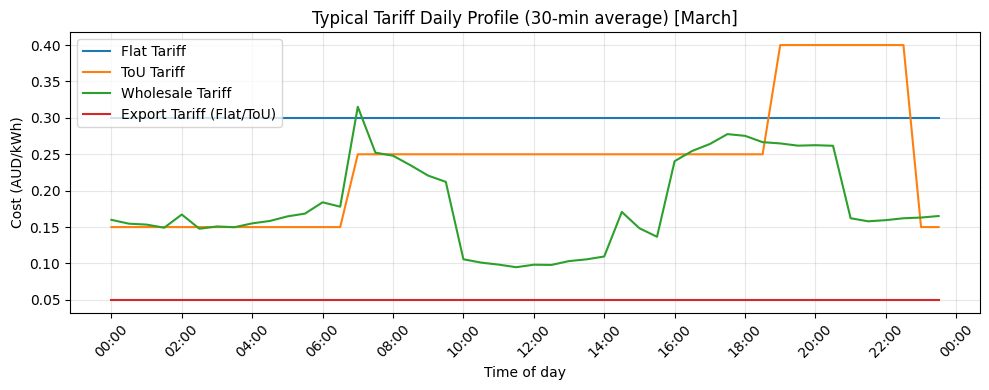

In [140]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(flat_graph["timestamp"], flat_graph["tariff_import_flat_AUD/kWh"], label = "Flat Tariff")
ax.plot(tou_graph["timestamp"], tou_graph["tariff_import_tou_AUD/kWh"], label = "ToU Tariff")
ax.plot(wholesale_graph["timestamp"], wholesale_graph["tariff_import_wholesale_AUD/kWh"], label = "Wholesale Tariff")
ax.plot(export_graph["timestamp"], export_graph["tariff_export_tou_AUD/kWh"], label = "Export Tariff (Flat/ToU)")

ax.set_title("Typical Tariff Daily Profile (30-min average) [March]")
ax.set_xlabel("Time of day")
ax.set_ylabel("Cost (AUD/kWh)")
ax.grid(True, alpha=0.3)
ax.legend(loc = "upper left")

# Show time-of-day nicely: ticks every 2 hours
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()

## Real vs Forecasted Wholesale Tariffs 

In [126]:
target_date = datetime.date(2024,3,16)
to_graph = df[df["date"] == target_date][["date", "time_label", "tariff_import_wholesale_AUD/kWh", "tariff_import_wholesale_forecast_AUD/kWh"]]

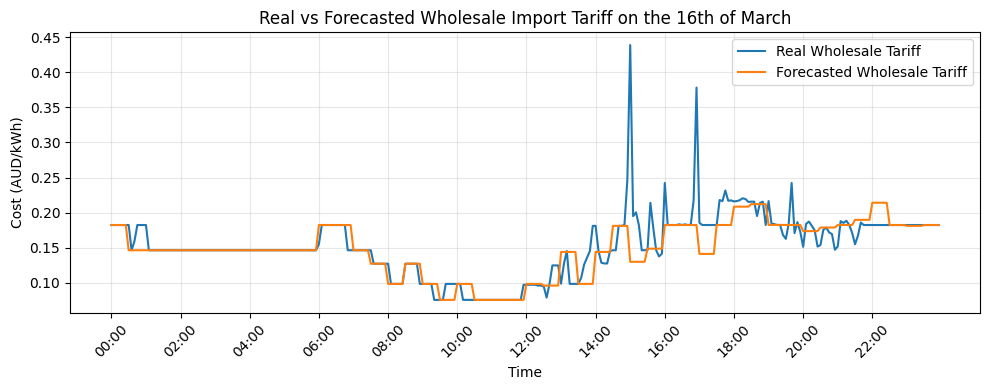

In [127]:
fig, ax = plt.subplots(figsize=(10,4))
ax.plot(to_graph["time_label"], to_graph["tariff_import_wholesale_AUD/kWh"], label = "Real Wholesale Tariff")
ax.plot(to_graph["time_label"], to_graph["tariff_import_wholesale_forecast_AUD/kWh"], label = "Forecasted Wholesale Tariff")
ax.set_title("Real vs Forecasted Wholesale Import Tariff on the 16th of March")
ax.set_xlabel("Time")
ax.set_ylabel("Cost (AUD/kWh)")
ax.grid(True, alpha=0.3)
ax.set_xticks(range(0, 288, 24))
ax.legend()
plt.xticks(rotation=45)
fig.tight_layout()

## Average Day Self Consumption

In [142]:
agg_sc = {"bess_sc_grid_import_kW":"mean",
          "bess_sc_grid_export_kW":"mean"}

df_sc_2023 = df_sc_2023.set_index("timestamp")
df_sc_30min = df_sc_2023.resample("30min").agg(agg).reset_index()
df_sc_2023 = df_sc_2023.reset_index()

import_graph = typical_daily_profile(df_sc_2023, 4, "bess_sc_grid_import_kW")
export_graph = typical_daily_profile(df_sc_2023, 4, "bess_sc_grid_export_kW")

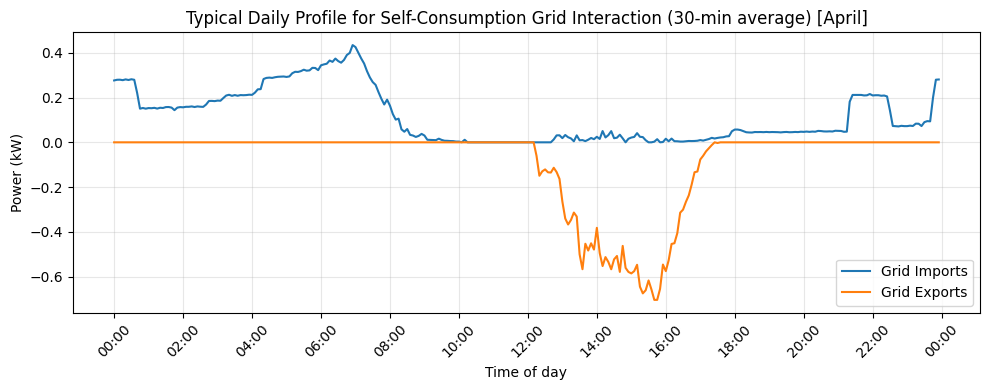

In [144]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(import_graph["timestamp"], import_graph["bess_sc_grid_import_kW"], label = "Grid Imports")
ax.plot(export_graph["timestamp"], -export_graph["bess_sc_grid_export_kW"], label = "Grid Exports")

ax.set_title("Typical Daily Profile for Self-Consumption Grid Interaction (30-min average) [April]")
ax.set_xlabel("Time of day")
ax.set_ylabel("Power (kW)")
ax.grid(True, alpha=0.3)
ax.legend(loc = "lower right")


# Show time-of-day nicely: ticks every 2 hours
ax.xaxis.set_major_locator(mdates.HourLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
plt.xticks(rotation=45)
plt.tight_layout()

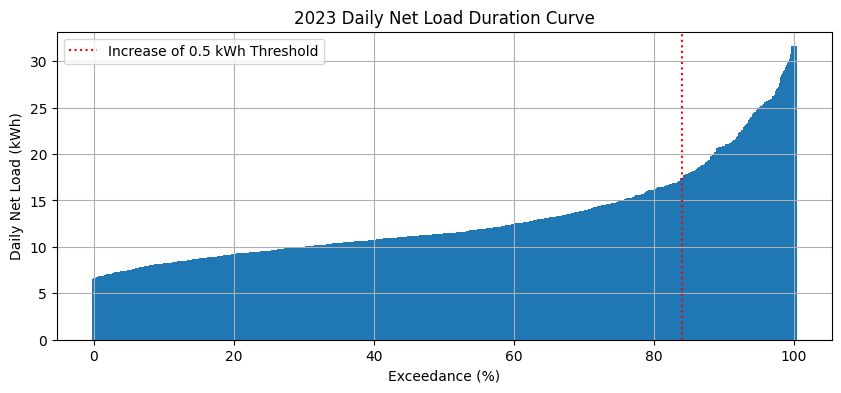

In [158]:
#From WK 4 workshop
fig, ax = plt.subplots(figsize=(10,4))

s = df_daily["positive_net_load_kWh"].sort_values(ascending=True)
s = s.reset_index(drop = True)
n = len(s)
pct = np.arange(1, n + 1) / n * 100
plt.bar(pct, s.to_numpy())
ax.set_xlabel("Exceedance (%)")
ax.set_ylabel("Daily Net Load (kWh)")
ax.set_title("2023 Daily Net Load Duration Curve")
plt.axvline(x=84, color='red', linestyle=':', label='Increase of 0.5 kWh Threshold')
ax.legend(loc = "upper left")
plt.grid(fig)
plt.close(fig)

fig

## Price vs PV Forecasting Comparison

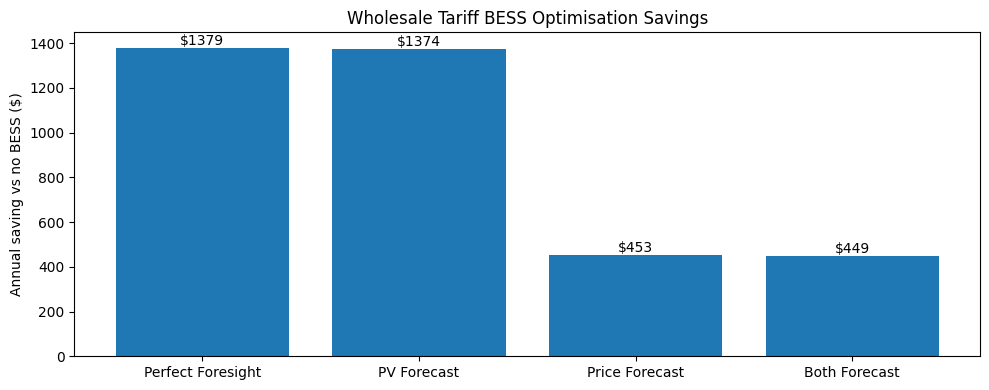

In [161]:
financial_values = [1378.87, 1374.44, 452.54, 449.32]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(["Perfect Foresight", "PV Forecast", "Price Forecast", "Both Forecast"], financial_values)
ax.bar_label(bars, fmt="$%.0f")
ax.set_ylabel("Annual saving vs no BESS ($)")
ax.set_title("Wholesale Tariff BESS Optimisation Savings")
plt.tight_layout()

## NPV against BESS price

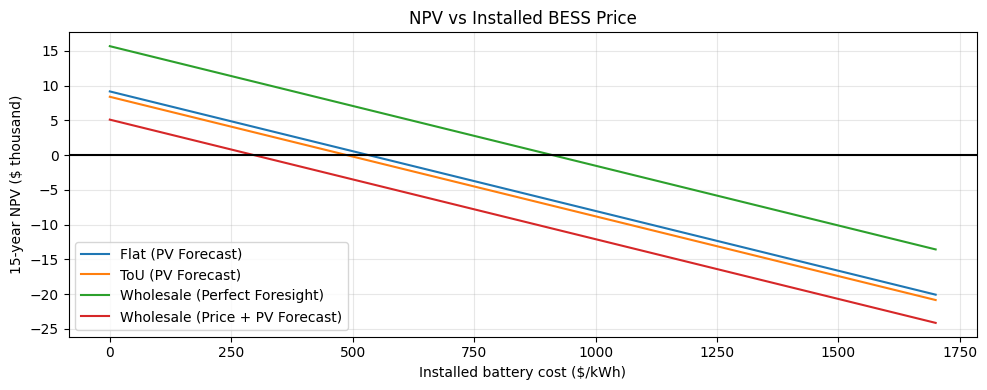

In [168]:
scenarios = {"Flat (PV Forecast)": 806.31, "ToU (PV Forecast)": 738.50,
             "Wholesale (Perfect Foresight)": 1378.87, "Wholesale (Price + PV Forecast)": 449.32}
prices = np.linspace(0, 1700, 200)

fig, ax = plt.subplots(figsize=(10, 4))
for scenario, savings in scenarios.items():
    ax.plot(prices, [npv(savings, price * BessParams.capacity_kWh) / 1000 for price in prices], label = scenario)
ax.set_xlabel("Installed battery cost ($/kWh)")
ax.set_ylabel("15-year NPV ($ thousand)")
ax.grid(True, alpha=0.3)
ax.axhline(0, color = "black")
ax.set_title("NPV vs Installed BESS Price")
ax.legend(loc = "lower left")
plt.tight_layout()